# Transported separatrix-connectivity barycenter reconstruction

This notebook reconstructs MSC-like barycenter topology from a saved PFGW bundle.

**Method.** Infer topology from transported exact adjacency and transported separatrix-local connectivity. Use `separatrixID` as the authoritative source of chain provenance. Soft paths remain inside one fixed recorded separatrix ID. Overlapping separatrices are retained without merging identities. `C_center` is used only for optional post-hoc comparison after the graph and all reconstruction parameters are fixed.

This notebook does not rerun the PFGW solver and does not claim an exact Morse–Smale complex without a later scalar-field realization.


## Configuration

Defaults are deterministic exploration settings, not theoretically optimal values. Reconstruction artifacts are written under `reconstruction/<name>_<mm-dd-yyyy-hh-mm-ss>/` inside the selected barycenter folder and do not overwrite previous reconstructions.

Set `DATA_KEYWORD` to the dataset, then choose among that dataset's saved barycenter folders with `BUNDLE_INDEX` (0 = newest) or `BUNDLE_RUN_NAME`. Optional `BUNDLE_PIPELINE` keeps only `shortestpath` or `lambda_converge` runs.


In [106]:
import importlib
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import Markdown, display

import lib.barycenter_io as barycenter_io
importlib.reload(barycenter_io)
from lib.barycenter_io import (
    load_barycenter_bundle,
    list_barycenter_bundles,
    print_barycenter_bundle_menu,
    select_barycenter_bundle,
)

import lib.msc_barycenter_reconstruction_separatrix as msc_barycenter_reconstruction_separatrix
importlib.reload(msc_barycenter_reconstruction_separatrix)
from lib.msc_barycenter_reconstruction_separatrix import (
    ReconstructionConfig,
    TERMINOLOGY_VERSION,
    validate_barycenter_bundle,
    decode_barycenter_nodes,
    compute_transported_separatrix_connectivity,
    construct_candidate_edge_table,
    infer_target_component_count,
    build_maximum_support_forest,
    augment_consensus_edges,
    local_repair_topology,
    validate_reconstructed_topology,
    run_q_hop_sensitivity,
    run_sampling_mode_sensitivity,
    compare_posthoc_baselines,
    build_evidence_density_field,
    route_graph_through_density,
    save_reconstruction_bundle,
    load_graph_pickle,
    verify_reloaded_topology,
    run_synthetic_separatrix_tests,
    graph_objective_components,
)

PROJECT_ROOT = Path(".").resolve()
DATA_KEYWORD = "synthetic"
# DATA_KEYWORD = "VortexStreet"
BUNDLE_PIPELINE = None  # None | "shortestpath" | "lambda_converge"
BUNDLE_INDEX = 0        # 0 = newest for this keyword; see printed table
BUNDLE_RUN_NAME = None  # e.g. "synthetic_08-29-2026-19-15-32"; overrides index

available = list_barycenter_bundles(
    PROJECT_ROOT / "results" / "barycenters",
    keyword=DATA_KEYWORD,
    pipeline=BUNDLE_PIPELINE,
)
print_barycenter_bundle_menu(
    available, keyword=DATA_KEYWORD, pipeline=BUNDLE_PIPELINE
)
selected = select_barycenter_bundle(
    DATA_KEYWORD,
    index=BUNDLE_INDEX,
    run_name=BUNDLE_RUN_NAME,
    pipeline=BUNDLE_PIPELINE,
    root=PROJECT_ROOT / "results" / "barycenters",
)
print(
    f"Using bundle [{selected.get('index')}] {selected['run_name']} "
    f"-> {Path(selected['path']).resolve()}"
)

config = ReconstructionConfig(
    run_name=selected["run_name"],
    reconstruction_name="transported_separatrix_connectivity",
    connectivity_affinity_mode="separatrix_gaussian",
    # d_sp is raw Euclidean / domain_size. σ is a fraction of the domain (not hops).
    gaussian_distance_units="domain",
    gaussian_sigma=0.05, # this works well for synthetic dataset
    # gaussian_sigma=0.03, # this works okay for VortexStreet dataset
    # η rescales the Gaussian; values are clipped so the peak cannot exceed 1.
    gaussian_eta=1.0,
    # True: K=0 at distance 0 (no self-loop affinity). Set False to keep the Gaussian peak.
    gaussian_zero_at_zero_distance=True,
    # Long-tail cutoff: K=0 when scaled shortest-path distance exceeds this many σ.
    gaussian_cutoff_sigmas=3.0,
    enable_density_routing=False,
    planarity_mode="hard",
)
BUNDLE_DIR = config.resolve_bundle_dir(PROJECT_ROOT)
OUTPUT_DIR, FIGURES_DIR = config.resolve_output_dirs(PROJECT_ROOT, create=True)
pd.DataFrame(
    [{"Setting": k, "Resolved value": v} for k, v in config.resolved_dict(PROJECT_ROOT).items()]
).head(20)


Bundles (keyword='synthetic'): 2
  [0] synthetic_lambda_converge_08-31-2026-16-51-54
      pipeline=lambda_converge  saved_at=08-31-2026-16-51-54  n_inputs=9  n_center=427
  [1] synthetic_08-31-2026-01-48-28
      pipeline=shortestpath  saved_at=08-31-2026-01-48-28  n_inputs=9  n_center=423
Using bundle [0] synthetic_lambda_converge_08-31-2026-16-51-54 -> C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\synthetic_lambda_converge_08-31-2026-16-51-54


,Setting,Resolved value
0,run_name,synthetic_lambda_converge_08-31-2026-16-51-54
1,reconstruction_name,transported_separatrix_connectivity
2,bundle_dir,C:\Users\mingz\desktop\MSCBarycenter\results\b...
3,random_seed,20260808
4,separatrix_id_attribute,separatrixID
5,separatrix_id_delimiter,","
6,missing_separatrix_id_policy,error
7,strict_separatrix_validation,True
8,allow_degree_based_chain_fallback,False
9,strict_validation,True


## Terminology used in this notebook

| Term | Meaning |
| --- | --- |
| Direct-adjacency support | Conditional consistency of exact input adjacency |
| Separatrix-connectivity support | Conditional consistency of nearby connectivity along one fixed recorded separatrix |
| Pair coverage | Amount of weighted correspondence information available for both endpoints |
| Direct-adjacency evidence | Coverage-weighted exact adjacency evidence |
| Separatrix-connectivity evidence | Coverage-weighted separatrix-local evidence |
| Soft-extension evidence | Evidence contributed by nearby-but-not-direct pairs |
| Connectivity-selection score | Explicit score used to rank candidate barycenter edges |

$$
E_{ij}^{\mathrm{direct}} = O_{ij} S_{ij}^{\mathrm{direct}}, \qquad
E_{ij}^{\mathrm{sep}} = O_{ij} S_{ij}^{\mathrm{sep}}.
$$

- High conditional support with low coverage is consistent but scarce evidence.
- High coverage with low direct support is evidence against exact adjacency.
- High separatrix support with low direct support indicates likely sampling mismatch along a shared separatrix.
- Support must not be interpreted without coverage.

Shared-separatrix membership is **not** transitive. Soft affinity paths must retain one fixed separatrix ID:

```text
u -- v -- w
edge (u, v): separatrixID = "0"
edge (v, w): separatrixID = "1"
```

Then $\Sigma(u)=\{0\}$, $\Sigma(v)=\{0,1\}$, $\Sigma(w)=\{1\}$, so $u$ and $w$ receive zero separatrix-local affinity even though their unrestricted hop distance is two.

The default Gaussian affinity uses geometric shortest-path length inside one separatrix ID, so equal physical distances stay comparable across sampling rates. Hop decay remains available as `separatrix_hop_decay`; it is tolerant to small sampling mismatches but is not invariant to nonuniform sampling density.


## Load and validate the barycenter bundle

Aligned inputs `Ts[s]`, `Cs[s]`, `Ys[s]`, `ps[s]`, `lambdas[s]`, `nodes_list[s]`, `Gs[s]`, and `mesh_ids[s]` are required. If couplings, graphs, or trustworthy node orderings are unavailable, reconstruction stops. There is no silent `C_center` fallback. A held-out seed is excluded from reconstruction and may appear only as a labeled post-hoc baseline.


In [107]:
bundle = load_barycenter_bundle(BUNDLE_DIR)
validation = validate_barycenter_bundle(bundle, strict_validation=config.strict_validation)
input_node_orders = validation.input_node_orders
print(
    f"Loaded {validation.n_inputs} inputs, n_center={validation.n_center}, "
    f"held_out_seed={validation.has_held_out_seed}, exclude_seed={validation.exclude_seed}"
)
for warning in validation.warnings:
    print("warning:", warning)
display(Markdown(f"`terminology_version = {TERMINOLOGY_VERSION}`"))


Loaded 9 inputs, n_center=427, held_out_seed=True, exclude_seed=True


`terminology_version = 4`

## Decode and inspect barycenter nodes


In [108]:
decoded = decode_barycenter_nodes(bundle, config)
nodes_df = decoded.dataframe.copy()
display(nodes_df.head())
print(
    "coordinates:", decoded.has_coordinates,
    "scalar:", decoded.has_scalar,
    "types:", decoded.has_types,
)
print(
    "effective constraints:",
    decoded.effective_type_constraint_mode,
    decoded.effective_scalar_order_constraint_mode,
    decoded.effective_planarity_mode,
)
nodes_df.to_csv(OUTPUT_DIR / "decoded_nodes.csv", index=False)


,node_id,x,y,z,scalar_normalized,scalar_value,morse_type,type_confidence,mass,coordinate_source,scalar_source,type_source
0,0,0.000000,0.000000,0.0,0.917458,0.504326,0,1.0,0.001233,features,features,features
1,1,0.000000,0.021297,0.0,0.928781,0.512632,1,1.0,0.001953,features,features,features
2,2,0.021377,0.000000,0.0,0.928781,0.512632,1,1.0,0.001953,features,features,features
3,3,0.218101,0.204749,0.0,0.127480,-0.075136,0,1.0,0.001744,features,features,features
4,4,0.230501,0.221655,0.0,0.190343,-0.029025,-1,1.0,0.003414,features,features,features


coordinates: True scalar: True types: True
effective constraints: soft soft hard


## Validate recorded separatrix annotations

Every input edge `separatrixID` is parsed as a set of IDs. A value such as `"0,1,3"` means the edge belongs independently to separatrices `"0"`, `"1"`, and `"3"`.


,input_index,node_count,edge_count,unique_separatrix_id_count,missing_separatrix_id_count,malformed_value_count,nodes_with_no_incident_id,multi_id_edge_fraction,maximum_ids_on_one_edge,disconnected_per_id_subgraph_count,non_path_like_per_id_subgraph_count,sampled_edge_length_median,sampled_edge_length_cv,fraction_edges_substantially_shorter_than_median
0,0,407,415,46,0,0,0,0.036145,2,0,0,0.02,0.184771,0.038554
1,1,433,442,56,0,0,0,0.036199,3,0,0,0.02,0.229646,0.061086
2,2,425,434,52,0,0,0,0.032258,3,0,0,0.02,0.208162,0.052995
3,3,410,418,48,0,0,0,0.026316,2,0,0,0.02,0.201693,0.050239
4,4,423,432,56,0,0,0,0.020833,2,0,0,0.02,0.213762,0.055556
5,5,413,421,48,0,0,0,0.035629,3,0,0,0.02,0.202669,0.049881
6,6,410,418,48,0,0,0,0.016746,2,0,0,0.02,0.207616,0.047847
7,7,435,444,58,0,0,0,0.033784,3,0,0,0.02,0.236044,0.067568
8,8,424,433,54,0,0,0,0.066975,3,0,0,0.02,0.217511,0.053118


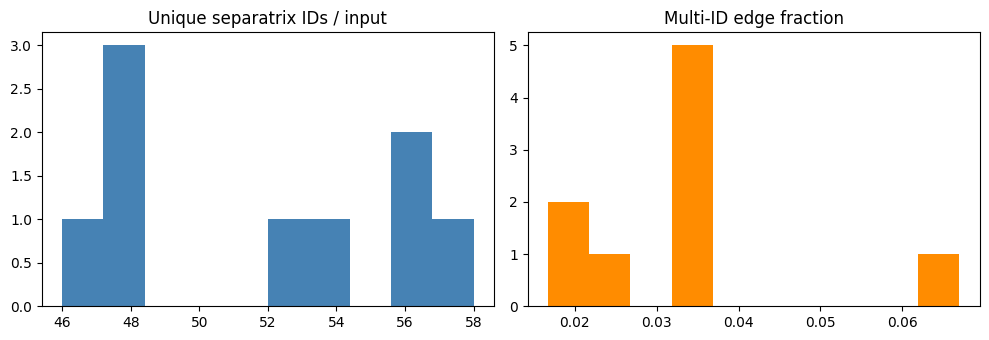

In [109]:
# Annotation diagnostics are computed during transport; run a lightweight preview first.
from lib.msc_barycenter_reconstruction_separatrix import (
    build_separatrix_membership,
    diagnose_separatrix_annotations,
)

preview_rows = []
for s, graph in enumerate(bundle["Gs"]):
    membership = build_separatrix_membership(
        graph,
        attribute=config.separatrix_id_attribute,
        delimiter=config.separatrix_id_delimiter,
        strict=config.strict_separatrix_validation,
        missing_policy=config.missing_separatrix_id_policy,
    )
    annotation, subgraph_df, _, _, sampling = diagnose_separatrix_annotations(
        graph, s, membership
    )
    preview_rows.append(annotation)
preview_df = pd.DataFrame(preview_rows)
display(preview_df)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(preview_df["unique_separatrix_id_count"], bins=10, color="steelblue")
axes[0].set_title("Unique separatrix IDs / input")
axes[1].hist(preview_df["multi_id_edge_fraction"], bins=10, color="darkorange")
axes[1].set_title("Multi-ID edge fraction")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "separatrix_annotation_preview.png", dpi=140)
plt.show()


## Build direct adjacency and separatrix-local affinities

## Build direct adjacency and separatrix-local affinities

Direct adjacency is exact binary adjacency. The default separatrix-local affinity is a Gaussian of **domain-normalized** geometric shortest-path distance inside one fixed separatrix ID.

Input graphs store **raw mesh coordinates**. Edge `weight` is the same unnormalized 3D Euclidean length. FGW features `Ys` and the barycenter relation `C` are separately normalized (`(x-min)/domain_size` and `1/max(SP)`). Gaussian \(K\) does **not** use those FGW-rescaled values. It takes raw Euclidean shortest-path length and divides by `domain_size`:

$$
d_{\mathrm{sp}}(u,v)=\frac{d_{\mathrm{raw}}(u,v)}{\texttt{domain\_size}},\qquad
K(u,v)=\eta\exp\left(-\frac{d_{\mathrm{sp}}(u,v)^{2}}{2\sigma^{2}}\right)
\quad\text{for }0 < d_{\mathrm{sp}} \le c\sigma,
$$

clipped to $[0,1]$. Then $\sigma$ is a **fraction of the domain** (try $0.02$–$0.1$). Transport diagnostics report `median_raw_edge_length`, `median_scaled_edge_length`, `domain_size`, and $\sigma$ in both raw and scaled units. Set `gaussian_distance_units="raw"` only if you want $\sigma$ in mesh coordinates.

If `gaussian_zero_at_zero_distance` is true, $K=0$ at $d_{\mathrm{sp}}=0$; if false, the peak $\eta$ is kept on the diagonal.


## Transport connectivity through PFGW couplings

Conditional supports answer different questions from pair coverage. Seed graphs held out of the barycenter are never included.


,value
n_inputs,9
n_center,427
lambda_sum,1.0
affinity_mode,separatrix_gaussian
gaussian_sigma,0.05
gaussian_eta,1.0
gaussian_zero_at_zero_distance,True
gaussian_cutoff_sigmas,3.0
gaussian_distance_units,domain
gaussian_distance_units_requested,domain


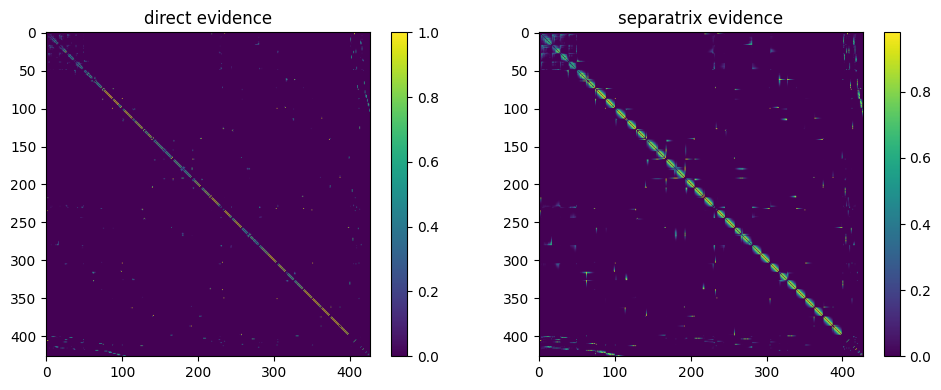

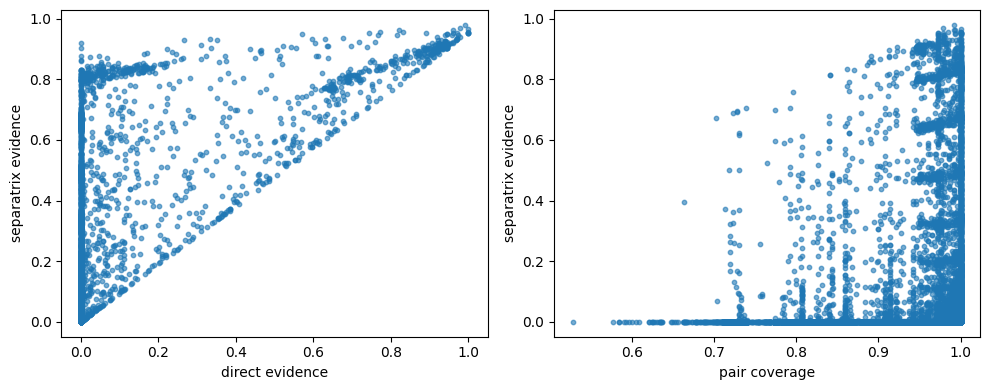

In [110]:
transported = compute_transported_separatrix_connectivity(
    bundle, input_node_orders, config
)
for warning in transported.warnings:
    print("warning:", warning)
display(pd.Series(transported.diagnostics, name="value").to_frame())

# Conditional support S is an intermediate for evidence E = O * S; show E only.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
matrices = [
    ("direct evidence", transported.direct_adjacency_evidence),
    ("separatrix evidence", transported.separatrix_connectivity_evidence),
]
for ax, (title, matrix) in zip(axes.ravel(), matrices):
    im = ax.imshow(np.nan_to_num(matrix, nan=0.0), cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "transported_connectivity_heatmaps.png", dpi=140)
plt.show()

upper = np.triu(transported.pair_is_covered, 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(
    transported.direct_adjacency_evidence[upper],
    transported.separatrix_connectivity_evidence[upper],
    s=10,
    alpha=0.6,
)
axes[0].set_xlabel("direct evidence")
axes[0].set_ylabel("separatrix evidence")
axes[1].scatter(
    transported.pair_coverage[upper],
    transported.separatrix_connectivity_evidence[upper],
    s=10,
    alpha=0.6,
)
axes[1].set_xlabel("pair coverage")
axes[1].set_ylabel("separatrix evidence")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "support_coverage_scatter.png", dpi=140)
plt.show()


## Visualize kernel \(K\) vs connectivity \(A\)

Per-input **connectivity** \(A\) is binary adjacency. **Kernel** \(K\) is the Gaussian (or hop-decay) separatrix-local affinity. Soft pairs are those with \(K>0\) and \(A=0\). Change `kernel_viz_input_index` to inspect another input.


,input_index,n_nodes,direct_pairs,positive_K_pairs,soft_only_pairs,mean_K_on_direct,mean_K_on_soft,max_K,max_K_minus_A
0,0,407,415,2714,2299,0.961618,0.410512,0.999722,0.975317
1,1,433,442,2738,2296,0.962619,0.422017,0.999722,0.987766
2,2,425,434,2676,2242,0.962313,0.430004,0.999722,0.974426
3,3,410,418,2653,2235,0.962262,0.418239,0.999722,0.975317
4,4,423,432,2537,2105,0.962382,0.436430,0.999722,0.975317
5,5,413,421,2705,2284,0.962218,0.415573,0.999722,0.969920
6,6,410,418,2608,2190,0.962048,0.420197,0.999722,0.975317
7,7,435,444,2709,2265,0.962942,0.425726,0.999722,0.990050
8,8,424,433,2702,2269,0.962535,0.422042,0.999722,0.975317


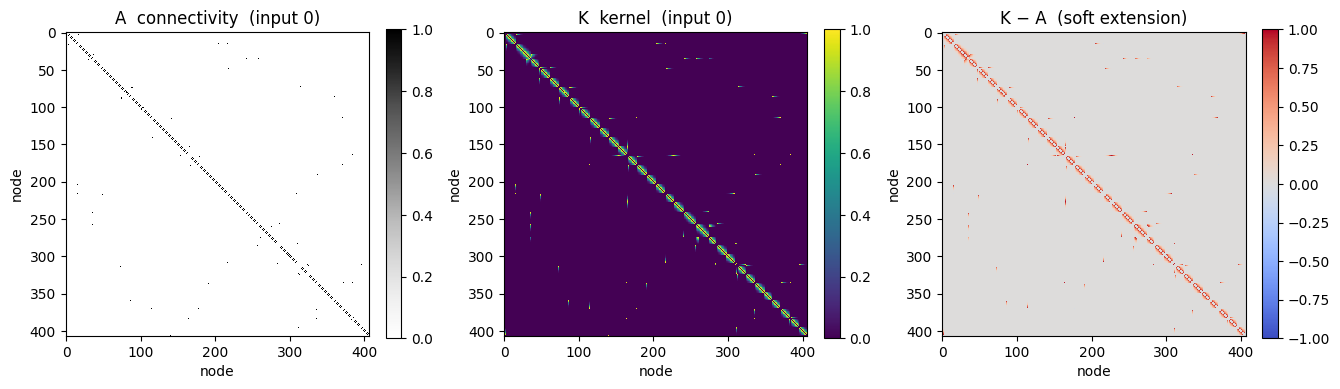

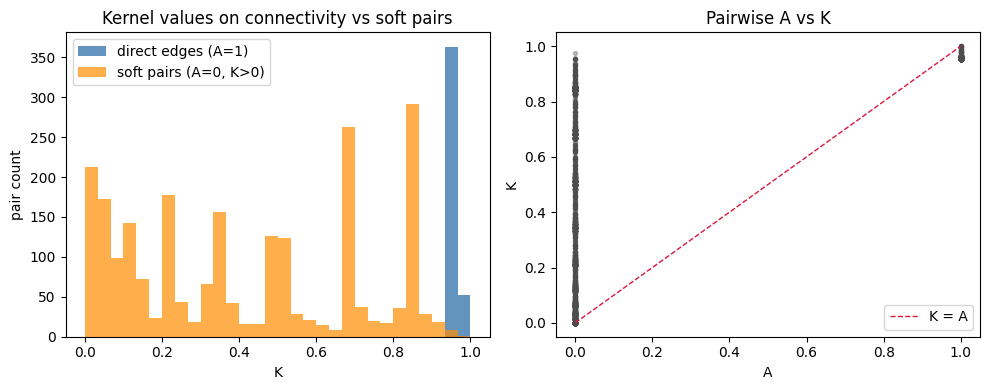

In [111]:
kernel_viz_input_index = 0
n_kernel_inputs = len(transported.input_separatrix_affinities)
if not (0 <= kernel_viz_input_index < n_kernel_inputs):
    raise IndexError(
        f"kernel_viz_input_index={kernel_viz_input_index} is out of range "
        f"for {n_kernel_inputs} inputs."
    )

kernel_rows = []
for s, (A_s, K_s) in enumerate(
    zip(
        transported.input_direct_adjacency_matrices,
        transported.input_separatrix_affinities,
    )
):
    A_s = np.asarray(A_s, dtype=float)
    K_s = np.asarray(K_s, dtype=float)
    ii, jj = np.triu_indices(A_s.shape[0], 1)
    a = A_s[ii, jj]
    k = K_s[ii, jj]
    direct = a > 0
    soft = (k > 1e-12) & ~direct
    kernel_rows.append(
        {
            "input_index": s,
            "n_nodes": int(A_s.shape[0]),
            "direct_pairs": int(direct.sum()),
            "positive_K_pairs": int((k > 1e-12).sum()),
            "soft_only_pairs": int(soft.sum()),
            "mean_K_on_direct": float(k[direct].mean()) if np.any(direct) else np.nan,
            "mean_K_on_soft": float(k[soft].mean()) if np.any(soft) else np.nan,
            "max_K": float(k.max()) if k.size else np.nan,
            "max_K_minus_A": float((K_s - A_s)[ii, jj].max()) if k.size else np.nan,
        }
    )
kernel_summary_df = pd.DataFrame(kernel_rows)
display(kernel_summary_df)

A = np.asarray(transported.input_direct_adjacency_matrices[kernel_viz_input_index], dtype=float)
K = np.asarray(transported.input_separatrix_affinities[kernel_viz_input_index], dtype=float)
delta = K - A
ii, jj = np.triu_indices(A.shape[0], 1)
a_u, k_u = A[ii, jj], K[ii, jj]
direct_u = a_u > 0
soft_u = (k_u > 1e-12) & ~direct_u

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
for ax, title, matrix, cmap, vlim in (
    (axes[0], f"A  connectivity  (input {kernel_viz_input_index})", A, "Greys", (0.0, 1.0)),
    (axes[1], f"K  kernel  (input {kernel_viz_input_index})", K, "viridis", (0.0, 1.0)),
    (axes[2], "K − A  (soft extension)", delta, "coolwarm", (-1.0, 1.0)),
):
    im = ax.imshow(matrix, cmap=cmap, vmin=vlim[0], vmax=vlim[1], interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("node")
    ax.set_ylabel("node")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"kernel_vs_connectivity_input{kernel_viz_input_index}.png", dpi=140)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(
    k_u[direct_u],
    bins=30,
    range=(0.0, 1.0),
    color="steelblue",
    alpha=0.85,
    label="direct edges (A=1)",
)
if np.any(soft_u):
    axes[0].hist(
        k_u[soft_u],
        bins=30,
        range=(0.0, 1.0),
        color="darkorange",
        alpha=0.7,
        label="soft pairs (A=0, K>0)",
    )
axes[0].set_xlabel("K")
axes[0].set_ylabel("pair count")
axes[0].set_title("Kernel values on connectivity vs soft pairs")
axes[0].legend()
axes[1].scatter(a_u, k_u, s=8, alpha=0.35, c="0.3")
axes[1].plot([0, 1], [0, 1], color="crimson", lw=1, ls="--", label="K = A")
axes[1].set_xlabel("A")
axes[1].set_ylabel("K")
axes[1].set_title("Pairwise A vs K")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"kernel_vs_connectivity_scatter_input{kernel_viz_input_index}.png", dpi=140)
plt.show()


## Visualize evidence as thresholded edge overlays

Conditional support $S$ is an intermediate for evidence $E=O\cdot S$. Before candidate selection and skeleton construction, inspect the transported evidence matrices geometrically: draw every barycenter pair whose evidence exceeds a notebook-local threshold, laid out with the decoded node coordinates.

| Matrix | Role |
| --- | --- |
| Direct-adjacency evidence | Coverage-weighted exact adjacency |
| Separatrix-connectivity evidence | Coverage-weighted separatrix-local connectivity |

Edge color and transparency follow a sequential colormap of the retained weights. `MIN_EDGE_THRESHOLD` and `MIN_TRANSPARENCY` live only in this section for quick tuning and are not reconstruction config.


figure axes=3 (expect 4 = 2 plots + 2 colorbars); cmaps=['blues_dark_edges']


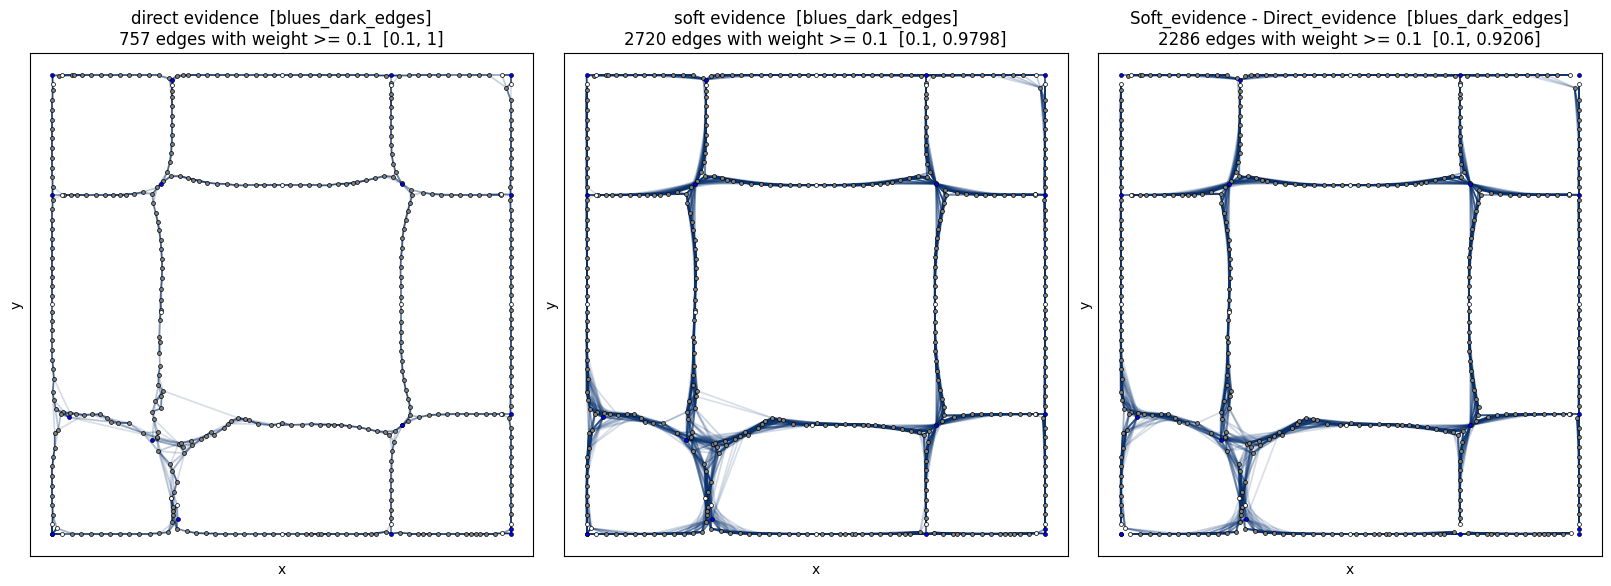

,view,edge_count,w_min,w_max,cmap
0,direct evidence,757,0.100021,1.000000,blues_dark_edges
1,soft evidence,2720,0.100042,0.979765,blues_dark_edges
2,Soft_evidence - Direct_evidence,2286,0.100042,0.920620,blues_dark_edges


In [141]:
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from lib.msc_plotting import draw_msc_nodes, set_barycenter_axes_limits

# Intermediate visualization knobs (notebook-local; not ReconstructionConfig)
MIN_EDGE_THRESHOLD = 0.10
MIN_TRANSPARENCY = min(1.0, MIN_EDGE_THRESHOLD * 1.50)


def draw_barycenter_weighted_edges(
    weight_matrix,
    min_edge_threshold,
    min_transparency,
    *,
    nodes_df,
    title=None,
    cmap=None,
    ax=None,
    figsize=(8, 7),
    edge_width=1.25,
    node_size=8,
):
    """Draw all barycenter pairs with weight >= threshold using node coordinates.

    Default colormap is a truncated Blues map (no near-white samples), not viridis.
    Each call adds a colorbar for the retained edge weights on the target axes.
    """
    W = np.asarray(weight_matrix, dtype=float)
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError(f"weight_matrix must be square; got shape {W.shape}.")
    min_transparency = float(np.clip(min_transparency, 0.0, 1.0))
    n = W.shape[0]

    # IMPORTANT: build the colormap inside this function.
    # Truncated Blues avoids white/yellow washout on a white background.
    if cmap is None:
        blues = plt.get_cmap("Blues")
        cmap_obj = LinearSegmentedColormap.from_list(
            "blues_dark_edges",
            blues(np.linspace(0.99, 1.00, 256)),
        )
    elif isinstance(cmap, str):
        cmap_obj = plt.get_cmap(cmap)
    else:
        cmap_obj = cmap

    pos = {
        int(row.node_id): np.array([float(row.x), float(row.y)], dtype=float)
        for row in nodes_df.itertuples(index=False)
        if np.isfinite(row.x) and np.isfinite(row.y)
    }
    if len(pos) != n:
        raise ValueError(
            f"Need finite (x, y) for all {n} barycenter nodes; got {len(pos)}."
        )

    iu, ju = np.triu_indices(n, k=1)
    weights = W[iu, ju]
    keep = np.isfinite(weights) & (weights >= float(min_edge_threshold))
    iu, ju, weights = iu[keep], ju[keep], weights[keep]

    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    else:
        fig = ax.figure

    if weights.size:
        w_min = float(weights.min())
        w_max = float(weights.max())
        if w_max > w_min:
            t = (weights - w_min) / (w_max - w_min)
        else:
            t = np.ones(len(weights), dtype=float)

        # Color from the sequential map; alpha also scales with weight.
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[:, 3] = min_transparency + (1.0 - min_transparency) * t
        segments = [[pos[int(u)], pos[int(v)]] for u, v in zip(iu, ju)]
        ax.add_collection(
            LineCollection(segments, colors=rgba, linewidths=edge_width, zorder=1)
        )

        norm = Normalize(vmin=w_min, vmax=w_max if w_max > w_min else w_min + 1e-12)
        mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        mappable.set_array([])
        # cbar = fig.colorbar(mappable, ax=ax, fraction=0.046, pad=0.04)
        # cbar.set_label("edge weight")
    else:
        w_min = w_max = float("nan")

    G_nodes = nx.Graph()
    for row in nodes_df.itertuples(index=False):
        node_id = int(row.node_id)
        attrs = {}
        morse = getattr(row, "morse_type", np.nan)
        if morse is not None and not pd.isna(morse):
            attrs["type"] = int(morse)
        G_nodes.add_node(node_id, **attrs)
    draw_msc_nodes(G_nodes, pos, ax, regular_size=node_size, critical_size=node_size)
    set_barycenter_axes_limits(ax, pos)

    cmap_name = getattr(cmap_obj, "name", type(cmap_obj).__name__)
    label = title or "weighted edges"
    ax.set_title(
        f"{label}  [{cmap_name}]\n"
        f"{len(weights)} edges with weight >= {min_edge_threshold:g}"
        + (f"  [{w_min:.4g}, {w_max:.4g}]" if weights.size else "")
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    return {
        "edge_count": int(weights.size),
        "w_min": w_min,
        "w_max": w_max,
        "cmap": cmap_name,
    }


weight_views = [
    ("direct evidence", transported.direct_adjacency_evidence),
    ("soft evidence", transported.separatrix_connectivity_evidence),
    ("Soft_evidence - Direct_evidence", transported.separatrix_connectivity_evidence - transported.direct_adjacency_evidence)
]

# constrained layout keeps per-axes colorbars visible (avoid tight_layout clipping)

if "VortexStreet" in DATA_KEYWORD:
    fig, axes = plt.subplots(3, 1, figsize=(16, 8), layout="constrained")
else:
    fig, axes = plt.subplots(1, 3, figsize=(16, 8), layout="constrained")
summaries = []
for ax, (title, matrix) in zip(axes.ravel(), weight_views):
    summary = draw_barycenter_weighted_edges(
        matrix,
        MIN_EDGE_THRESHOLD,
        MIN_TRANSPARENCY,
        nodes_df=nodes_df,
        title=title,
        ax=ax,
    )
    summaries.append({"view": title, **summary})

print(
    f"figure axes={len(fig.axes)} "
    f"(expect 4 = 2 plots + 2 colorbars); "
    f"cmaps={sorted({s['cmap'] for s in summaries})}"
)
fig.savefig(FIGURES_DIR / "evidence_thresholded_overlays.png", dpi=140)
plt.show()
display(pd.DataFrame(summaries))


## Separatrix-aware triangle reconstruction

Keep the evidence graphs above unchanged. This section asks a narrower question: if we threshold the **same** evidence matrices at `MIN_EDGE_THRESHOLD` and delete only local chords whose FPGW couplings place an intermediate barycenter node on a common **input 1-separatrix**, do the graphs become cleaner?

The method is local and combinatorial:

1. Build a candidate graph from pairs with evidence $\ge$ `MIN_EDGE_THRESHOLD` (the visualization floor; not a new parameter).
2. Condition each coupling so $q_i(x\mid u)$ is the correspondence of barycenter $u$ in input $i$.
3. Score $B(a,b,c)$: the coverage-weighted probability that $b$ lies **strictly between** $a$ and $c$ on at least one recorded simple 1-separatrix path.
4. For a frozen candidate triangle $a{-}b{-}c$, treat $(a,c)$ as a redundant shortcut when $B(a,b,c)\ge\theta$.
5. Collect every redundant edge, then delete them **simultaneously**.

This is not a Euclidean straightness test and not a weakest-edge-of-the-triangle rule. A 1-separatrix may be strongly curved. Direct and soft evidence are reconstructed independently with the same routine.

Default: `tau_evidence = MIN_EDGE_THRESHOLD` (0.1), `theta = 0.5`. Path-level (non-triangle) redundancy is out of scope here.


In [113]:
importlib.reload(msc_barycenter_reconstruction_separatrix)
from lib.msc_barycenter_reconstruction_separatrix import (
    apply_triangle_shortcut_threshold,
    candidate_graph_from_evidence,
    evidence_matrix_from_graph,
    prepare_separatrix_betweenness_engine,
    reconstruct_separatrix_triangle_shortcuts,
    run_triangle_reconstruction_tests,
)

TRIANGLE_THETA = 0.5
THETA_SWEEP = (0.4, 0.5, 0.6, 0.7)

synthetic_triangle_tests = run_triangle_reconstruction_tests()
assert all(synthetic_triangle_tests.values()), synthetic_triangle_tests
display(pd.Series(synthetic_triangle_tests, name="passed").to_frame())
print(
    f"tau_evidence = MIN_EDGE_THRESHOLD = {MIN_EDGE_THRESHOLD:g}; "
    f"theta = {TRIANGLE_THETA:g}"
)


,passed
A_ordered_triple,True
B_junction_does_not_invalidate,True
C_boolean_multi_id,True
D_coupling_symmetry,True
E_partial_matching,True
F_simultaneous_removal,True


tau_evidence = MIN_EDGE_THRESHOLD = 0.1; theta = 0.5


### Preprocess ordered 1-separatrices and conditional couplings

Each input `separatrixID` subgraph is a simple path. Paths are indexed in the **coupling column order** (`Ts[i]` has shape `(n_center, n_input)`: rows are barycenter nodes).

Coverage reuses the existing matched fractions

$$
r_i(u)=\min\bigl(1,\, m_i(u)/p(u)\bigr)
$$

already stored as `transported.matched_fractions`. For a triple, $w_i(a,b,c)=\min(r_i(a),r_i(b),r_i(c))$. An input that barely matches one of $a,b,c$ contributes almost no weight instead of voting “not between”. $B_i$ is a conditional probability, so input barycenter weights `lambdas` are not mixed in again (they are currently uniform).


In [114]:
betweenness_engine = prepare_separatrix_betweenness_engine(
    bundle,
    input_node_orders,
    config,
    transported,
)
path_diag = pd.DataFrame(
    [index.diagnostics for index in betweenness_engine.path_indices]
)
path_diag.insert(0, "input_index", range(len(path_diag)))
display(path_diag)
print(
    "conditional couplings Q_i:",
    [tuple(Q.shape) for Q in betweenness_engine.conditionals],
    "matched_fractions",
    betweenness_engine.matched_fractions.shape,
)


,input_index,n_nodes,n_separatrix_ids,n_between_pairs,skipped_non_path_ids,path_node_count_min,path_node_count_median,path_node_count_max
0,0,407,46,5104,0,2,13.0,21
1,1,433,56,5074,0,2,12.5,22
2,2,425,52,4774,0,2,13.0,18
3,3,410,48,4868,0,2,13.0,20
4,4,423,56,4486,0,2,11.5,19
5,5,413,48,5048,0,2,13.0,21
6,6,410,48,4680,0,2,13.0,16
7,7,435,58,4954,0,2,13.0,21
8,8,424,54,4924,0,2,13.0,20


conditional couplings Q_i: [(427, 407), (427, 433), (427, 425), (427, 410), (427, 423), (427, 413), (427, 410), (427, 435), (427, 424)] matched_fractions (9, 427)


### Reconstruct direct and soft candidate graphs

Soft evidence here is the notebook's overlay matrix `transported.separatrix_connectivity_evidence` (separatrix-local connectivity, including direct pairs), not the residual `soft_extension_evidence`.


In [115]:
# Direct and soft share this function; only the evidence matrix differs.
direct_triangle = reconstruct_separatrix_triangle_shortcuts(
    transported.direct_adjacency_evidence,
    betweenness_engine,
    min_edge_threshold=MIN_EDGE_THRESHOLD,
    theta=TRIANGLE_THETA,
    mode="direct",
)
soft_triangle = reconstruct_separatrix_triangle_shortcuts(
    transported.separatrix_connectivity_evidence,
    betweenness_engine,
    min_edge_threshold=MIN_EDGE_THRESHOLD,
    theta=TRIANGLE_THETA,
    mode="soft",
)

# TEST D on reconstructed triples: endpoint symmetry of B(a, b, c).
symmetry_records = []
for result in (direct_triangle, soft_triangle):
    sample = result.removed_edges.head(8)
    for row in sample.itertuples(index=False):
        if pd.isna(row.witness):
            continue
        forward = betweenness_engine.score(int(row.a), int(row.witness), int(row.c))
        reverse = betweenness_engine.score(int(row.c), int(row.witness), int(row.a))
        symmetry_records.append(
            {
                "mode": result.mode,
                "a": int(row.a),
                "b": int(row.witness),
                "c": int(row.c),
                "B_abc": forward.B,
                "B_cba": reverse.B,
                "abs_diff": abs(forward.B - reverse.B),
            }
        )
symmetry_df = pd.DataFrame(symmetry_records)
if len(symmetry_df):
    assert np.all(symmetry_df["abs_diff"] < 1e-10), symmetry_df
display(symmetry_df.head())

# TEST F: frozen-candidate scoring; permuting the scan order cannot change the kept edges.
_shuffled = list(direct_triangle.candidate_graph.edges())
rng = np.random.default_rng(0)
rng.shuffle(_shuffled)
direct_shuffled = reconstruct_separatrix_triangle_shortcuts(
    transported.direct_adjacency_evidence,
    betweenness_engine,
    min_edge_threshold=MIN_EDGE_THRESHOLD,
    theta=TRIANGLE_THETA,
    mode="direct",
    edge_order=_shuffled,
)
assert set(direct_triangle.reconstructed_graph.edges()) == set(
    direct_shuffled.reconstructed_graph.edges()
)
print("order-independence check passed")


,mode,a,b,c,B_abc,B_cba,abs_diff
0,direct,10,11,12,0.514460,0.514460,0.0
1,direct,10,12,13,0.643187,0.643187,0.0
2,direct,11,10,401,0.504661,0.504661,0.0
3,direct,12,10,401,0.637238,0.637238,0.0
4,direct,13,14,15,0.612091,0.612091,0.0


order-independence check passed


### Before / after visualizations

Left: reconstructed graph (original evidence on surviving edges). Right: the frozen candidate graph with **removed same-separatrix shortcuts in crimson** and retained edges in the same blue map as the evidence overlays. Layout is the decoded barycenter coordinates, so these plots are comparable to the thresholded evidence figures above.


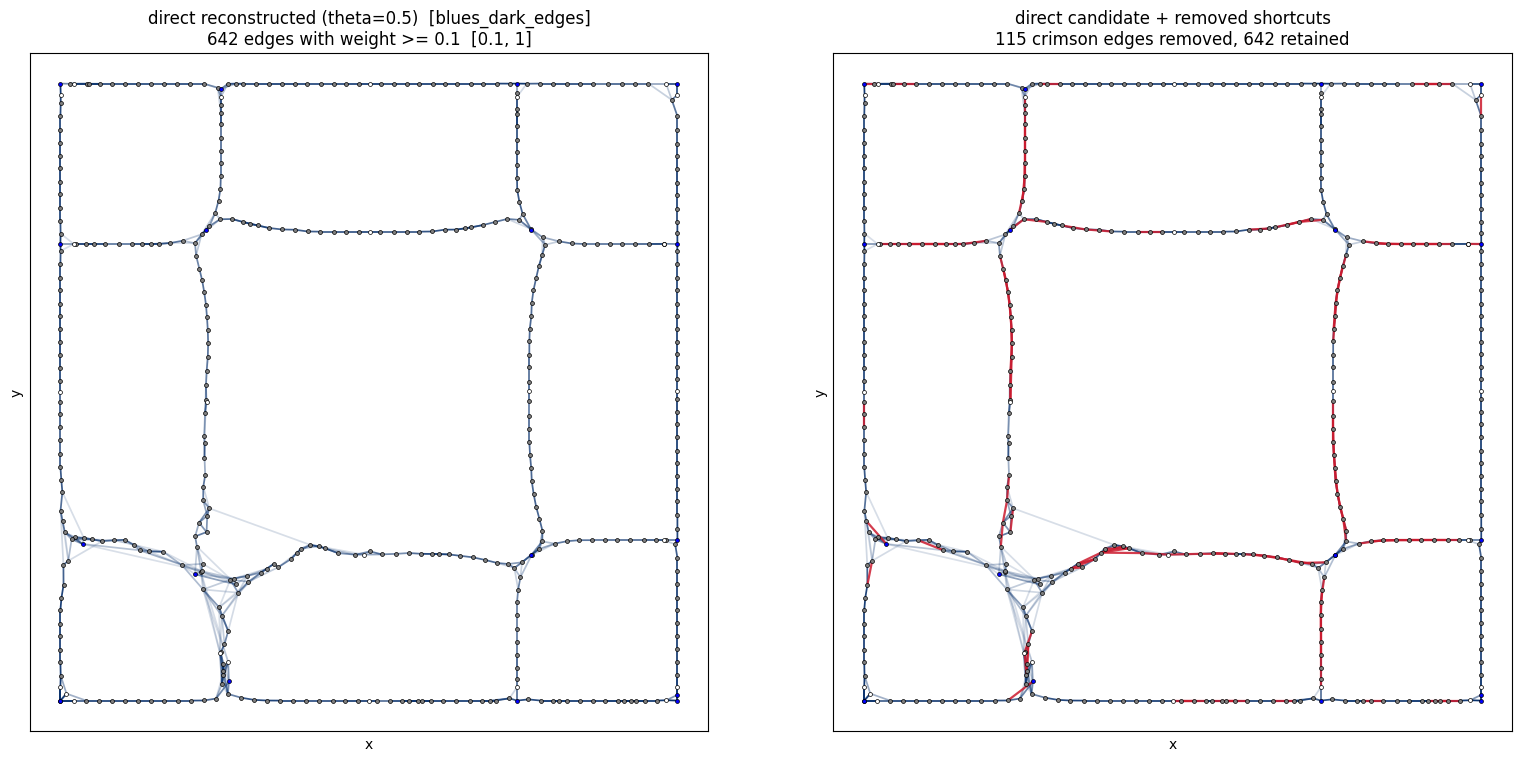

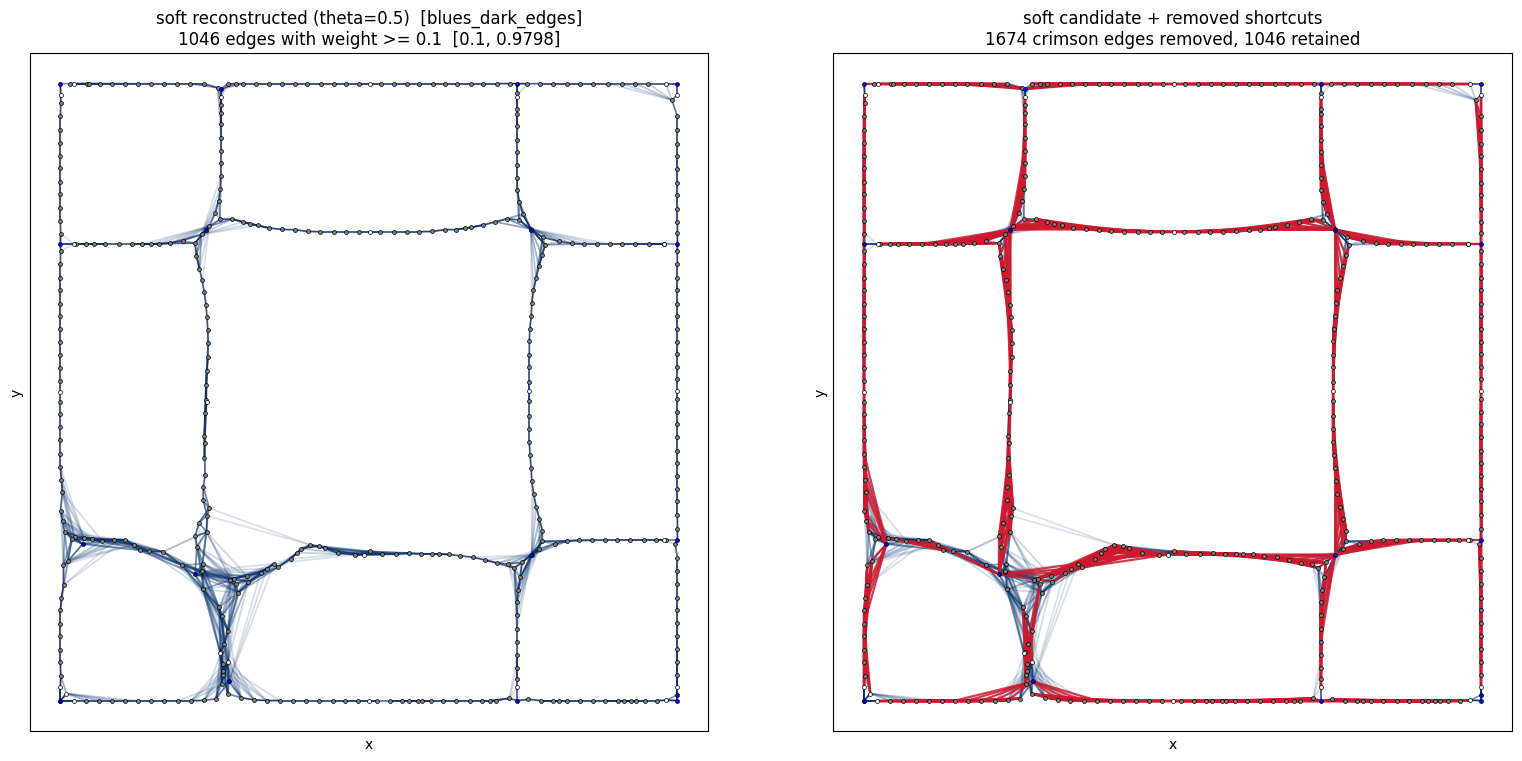

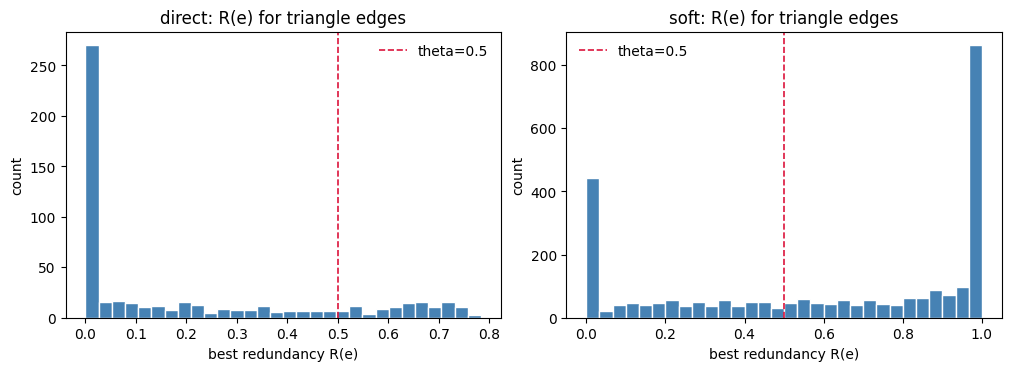

In [116]:
def _barycenter_plot_positions(nodes):
    return {
        int(row.node_id): np.array([float(row.x), float(row.y)], dtype=float)
        for row in nodes.itertuples(index=False)
        if np.isfinite(row.x) and np.isfinite(row.y)
    }


def _msc_node_graph(nodes):
    graph = nx.Graph()
    for row in nodes.itertuples(index=False):
        attrs = {}
        morse = getattr(row, "morse_type", np.nan)
        if morse is not None and not pd.isna(morse):
            attrs["type"] = int(morse)
        graph.add_node(int(row.node_id), **attrs)
    return graph


def draw_shortcut_diagnostic(
    result,
    *,
    nodes_df,
    ax,
    min_transparency=MIN_TRANSPARENCY,
    retained_width=1.25,
    removed_width=1.6,
):
    """Candidate graph with removed shortcuts drawn in crimson."""
    pos = _barycenter_plot_positions(nodes_df)
    n = result.candidate_graph.number_of_nodes()
    if len(pos) != n:
        raise ValueError(f"Need finite (x, y) for all {n} nodes; got {len(pos)}.")

    blues = plt.get_cmap("Blues")
    cmap_obj = LinearSegmentedColormap.from_list(
        "blues_dark_edges", blues(np.linspace(0.99, 1.00, 256))
    )
    removed = {
        tuple(sorted((int(a), int(c))))
        for a, c in zip(
            result.removed_edges["a"].to_numpy() if len(result.removed_edges) else [],
            result.removed_edges["c"].to_numpy() if len(result.removed_edges) else [],
        )
    }
    retained_uv, retained_w, removed_segments = [], [], []
    for u, v, data in result.candidate_graph.edges(data=True):
        edge = tuple(sorted((int(u), int(v))))
        if edge in removed:
            removed_segments.append([pos[edge[0]], pos[edge[1]]])
        else:
            retained_uv.append(edge)
            retained_w.append(float(data.get("evidence", 0.0)))

    if retained_w:
        weights = np.asarray(retained_w, dtype=float)
        w_min = float(weights.min())
        w_max = float(weights.max())
        t = (
            np.ones(len(weights), dtype=float)
            if w_max <= w_min
            else (weights - w_min) / (w_max - w_min)
        )
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[:, 3] = min_transparency + (1.0 - min_transparency) * t
        segments = [[pos[u], pos[v]] for u, v in retained_uv]
        ax.add_collection(
            LineCollection(segments, colors=rgba, linewidths=retained_width, zorder=1)
        )
    if removed_segments:
        ax.add_collection(
            LineCollection(
                removed_segments,
                colors=[(0.80, 0.10, 0.18, 0.85)],
                linewidths=removed_width,
                zorder=2,
            )
        )
    draw_msc_nodes(
        _msc_node_graph(nodes_df), pos, ax, regular_size=8, critical_size=8
    )
    set_barycenter_axes_limits(ax, pos)
    ax.set_title(
        f"{result.mode} candidate + removed shortcuts\n"
        f"{len(removed)} crimson edges removed, "
        f"{len(retained_uv)} retained"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")


def plot_triangle_reconstruction(result, *, nodes_df, figures_dir):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
    reconstructed_weights = evidence_matrix_from_graph(
        result.reconstructed_graph, n_nodes=result.candidate_graph.number_of_nodes()
    )
    draw_barycenter_weighted_edges(
        reconstructed_weights,
        MIN_EDGE_THRESHOLD,
        MIN_TRANSPARENCY,
        nodes_df=nodes_df,
        title=f"{result.mode} reconstructed (theta={result.theta:g})",
        ax=axes[0],
    )
    draw_shortcut_diagnostic(result, nodes_df=nodes_df, ax=axes[1])
    fig.savefig(
        figures_dir / f"triangle_reconstruction_{result.mode}.png", dpi=140
    )
    plt.show()
    return fig


plot_triangle_reconstruction(
    direct_triangle, nodes_df=nodes_df, figures_dir=FIGURES_DIR
)
plot_triangle_reconstruction(
    soft_triangle, nodes_df=nodes_df, figures_dir=FIGURES_DIR
)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, result in zip(axes, (direct_triangle, soft_triangle)):
    triangle_R = result.edge_scores.loc[
        result.edge_scores["in_triangle"], "redundancy"
    ]
    ax.hist(triangle_R.to_numpy(), bins=30, color="steelblue", edgecolor="white")
    ax.axvline(TRIANGLE_THETA, color="crimson", ls="--", lw=1.2, label=f"theta={TRIANGLE_THETA}")
    ax.set_title(f"{result.mode}: R(e) for triangle edges")
    ax.set_xlabel("best redundancy R(e)")
    ax.set_ylabel("count")
    ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "triangle_redundancy_histograms.png", dpi=140)
plt.show()


### Reconstruction statistics

`beta_0` is the number of connected components. `beta_1 = |E| - |V| + beta_0` is the cycle rank of the undirected graph. Removed-edge tables keep the original evidence, $R(a,c)$, the witness $b^*$, and per-input $B_i$ / coverage weights.


In [117]:
def _expand_removed_diagnostics(removed, n_inputs):
    if removed is None or len(removed) == 0:
        return pd.DataFrame()
    out = removed.copy().reset_index(drop=True)
    B = np.vstack(out["B_inputs"].to_numpy())
    W = np.vstack(out["weights"].to_numpy())
    for i in range(int(n_inputs)):
        out[f"B_{i}"] = B[:, i]
        out[f"w_{i}"] = W[:, i]
    return out.drop(columns=["B_inputs", "weights"])


stat_rows = []
for result in (direct_triangle, soft_triangle):
    stat_rows.append({"mode": result.mode, "theta": result.theta, **result.statistics})
reconstruction_stats = pd.DataFrame(stat_rows)
display(reconstruction_stats)

n_inputs = betweenness_engine.n_inputs
direct_removed_diag = _expand_removed_diagnostics(
    direct_triangle.removed_edges, n_inputs
)
soft_removed_diag = _expand_removed_diagnostics(
    soft_triangle.removed_edges, n_inputs
)
direct_removed_diag.to_csv(OUTPUT_DIR / "triangle_removed_edges_direct.csv", index=False)
soft_removed_diag.to_csv(OUTPUT_DIR / "triangle_removed_edges_soft.csv", index=False)
display(Markdown("**Direct removed edges** (first rows)"))
display(direct_removed_diag.head(12))
display(Markdown("**Soft removed edges** (first rows)"))
display(soft_removed_diag.head(12))


,mode,theta,n_nodes,n_candidate_edges,n_removed,n_reconstructed_edges,beta_0,beta_1,removed_B_min,removed_B_median,removed_B_max,triangle_edge_count,triangle_R_min,triangle_R_median,triangle_R_max
0,direct,0.5,427,757,115,642,1,216,0.501715,0.651895,0.783592,569,0.0,0.049324,0.783592
1,soft,0.5,427,2720,1674,1046,1,620,0.500230,0.973601,1.000000,2711,0.0,0.719277,1.000000


**Direct removed edges** (first rows)

,a,c,evidence,n_common_neighbors,redundancy,witness,uninformative,weight_sum,in_triangle,B_0,...,B_4,w_4,B_5,w_5,B_6,w_6,B_7,w_7,B_8,w_8
0,10,12,0.222495,3,0.514460,11.0,False,8.639146,True,0.983436,...,0.000000,1.0,0.989605,1.0,0.687904,0.639146,0.955441,1.000000,0.538470,1.0
1,10,13,0.133159,2,0.643187,12.0,False,9.000000,True,1.000000,...,0.000000,1.0,0.978224,1.0,0.705542,1.000000,0.937536,1.000000,0.944120,1.0
2,11,401,0.105829,3,0.504661,10.0,False,8.639146,True,0.973761,...,0.087898,1.0,0.996549,1.0,0.959802,0.639146,0.936989,1.000000,0.315239,1.0
3,12,401,0.106141,2,0.637238,10.0,False,9.000000,True,0.977412,...,0.000000,1.0,0.996549,1.0,0.988612,1.000000,0.936989,1.000000,0.546193,1.0
4,13,15,0.105193,4,0.612091,14.0,False,9.000000,True,1.000000,...,0.000000,1.0,0.000000,1.0,0.943813,1.000000,1.000000,1.000000,0.687024,1.0
5,13,280,0.127845,2,0.540722,415.0,False,9.000000,True,0.934257,...,0.000000,1.0,0.000000,1.0,0.916307,1.000000,1.000000,1.000000,0.000000,1.0
6,13,415,0.151020,4,0.505416,14.0,False,9.000000,True,0.549872,...,0.000000,1.0,0.000000,1.0,0.413715,1.000000,0.847357,1.000000,0.892540,1.0
7,15,414,0.145586,3,0.523547,14.0,False,9.000000,True,0.996743,...,0.000000,1.0,0.000000,1.0,0.907136,1.000000,0.754309,1.000000,0.311002,1.0
8,16,276,0.248618,1,0.568778,277.0,False,7.562258,True,0.971557,...,0.012044,1.0,0.790652,1.0,0.824772,1.000000,0.000000,0.369356,0.946321,1.0
9,16,280,0.115797,1,0.501715,279.0,False,7.562258,True,0.810077,...,0.864644,1.0,0.000000,1.0,0.066507,1.000000,0.966573,0.369356,0.084614,1.0


**Soft removed edges** (first rows)

,a,c,evidence,n_common_neighbors,redundancy,witness,uninformative,weight_sum,in_triangle,B_0,...,B_4,w_4,B_5,w_5,B_6,w_6,B_7,w_7,B_8,w_8
0,1,236,0.820756,6,0.970391,235.0,False,8.772546,True,0.855182,...,1.0,0.965968,0.885073,1.000000,1.0,0.993321,1.0,0.949849,1.0,0.964092
1,1,237,0.667839,6,0.991395,236.0,False,8.772501,True,0.961897,...,1.0,0.965968,0.962614,1.000000,1.0,0.993321,1.0,0.949803,1.0,0.964092
2,1,238,0.487976,6,1.000000,236.0,False,8.772501,True,1.000000,...,1.0,0.965968,1.000000,1.000000,1.0,0.993321,1.0,0.949803,1.0,0.964092
3,1,239,0.336873,6,1.000000,236.0,False,8.772546,True,1.000000,...,1.0,0.965968,1.000000,1.000000,1.0,0.993321,1.0,0.949849,1.0,0.964092
4,1,240,0.206085,6,1.000000,236.0,False,8.772546,True,1.000000,...,1.0,0.965968,1.000000,1.000000,1.0,0.993321,1.0,0.949849,1.0,0.964092
5,1,241,0.118307,6,1.000000,236.0,False,8.762554,True,1.000000,...,1.0,0.965968,1.000000,1.000000,1.0,0.993321,1.0,0.949849,1.0,0.964092
6,2,219,0.746488,6,0.982202,218.0,False,8.046708,True,0.903103,...,1.0,0.965968,0.907188,0.727132,1.0,0.993321,1.0,0.715321,1.0,0.964092
7,2,220,0.604311,6,1.000000,218.0,False,8.046708,True,1.000000,...,1.0,0.965968,1.000000,0.727132,1.0,0.993321,1.0,0.715321,1.0,0.964092
8,2,221,0.442330,6,1.000000,218.0,False,8.046708,True,1.000000,...,1.0,0.965968,1.000000,0.727132,1.0,0.993321,1.0,0.715321,1.0,0.964092
9,2,222,0.305002,6,1.000000,218.0,False,8.046708,True,1.000000,...,1.0,0.965968,1.000000,0.727132,1.0,0.993321,1.0,0.715321,1.0,0.964092


### Theta sensitivity

Scores $R(e)$ are computed once on the frozen candidate graph. Only the cutoff $\theta\in\{0.4,0.5,0.6,0.7\}$ changes. No value is selected as optimal; the table is only to see whether the reconstruction is stable on a reasonable consensus range.


In [118]:
sensitivity_rows = []
for result in (direct_triangle, soft_triangle):
    for theta in THETA_SWEEP:
        swept = apply_triangle_shortcut_threshold(
            result.candidate_graph,
            result.edge_scores,
            theta=theta,
            mode=result.mode,
            min_edge_threshold=MIN_EDGE_THRESHOLD,
        )
        sensitivity_rows.append(
            {
                "mode": result.mode,
                "theta": theta,
                **swept.statistics,
            }
        )
theta_sensitivity = pd.DataFrame(sensitivity_rows)
display(theta_sensitivity)
theta_sensitivity.to_csv(OUTPUT_DIR / "triangle_theta_sensitivity.csv", index=False)


,mode,theta,n_nodes,n_candidate_edges,n_removed,n_reconstructed_edges,beta_0,beta_1,removed_B_min,removed_B_median,removed_B_max,triangle_edge_count,triangle_R_min,triangle_R_median,triangle_R_max
0,direct,0.4,427,757,139,618,1,192,0.403211,0.630590,0.783592,569,0.0,0.049324,0.783592
1,direct,0.5,427,757,115,642,1,216,0.501715,0.651895,0.783592,569,0.0,0.049324,0.783592
2,direct,0.6,427,757,83,674,1,248,0.602191,0.677824,0.783592,569,0.0,0.049324,0.783592
3,direct,0.7,427,757,32,725,1,299,0.700588,0.729268,0.783592,569,0.0,0.049324,0.783592
4,soft,0.4,427,2720,1805,915,1,489,0.400827,0.952360,1.000000,2711,0.0,0.719277,1.000000
5,soft,0.5,427,2720,1674,1046,1,620,0.500230,0.973601,1.000000,2711,0.0,0.719277,1.000000
6,soft,0.6,427,2720,1524,1196,1,770,0.600572,0.986796,1.000000,2711,0.0,0.719277,1.000000
7,soft,0.7,427,2720,1383,1337,1,911,0.700588,0.996267,1.000000,2711,0.0,0.719277,1.000000


### Interpretation


In [119]:
def _interpret_result(result):
    stats = result.statistics
    n_cand = stats["n_candidate_edges"]
    n_rem = stats["n_removed"]
    frac = (n_rem / n_cand) if n_cand else 0.0
    return (
        f"- **{result.mode}:** {n_rem} / {n_cand} candidate edges pruned "
        f"({frac:.1%}), leaving {stats['n_reconstructed_edges']} edges, "
        f"beta_0={stats['beta_0']}, beta_1={stats['beta_1']}. "
        f"Removed-edge B range "
        f"[{stats['removed_B_min']:.3f}, {stats['removed_B_max']:.3f}] "
        f"(median {stats['removed_B_median']:.3f})."
    )


direct_frac = (
    direct_triangle.statistics["n_removed"]
    / max(direct_triangle.statistics["n_candidate_edges"], 1)
)
soft_frac = (
    soft_triangle.statistics["n_removed"]
    / max(soft_triangle.statistics["n_candidate_edges"], 1)
)
direct_beta = direct_triangle.statistics["beta_1"]
soft_beta = soft_triangle.statistics["beta_1"]
soft_theta_counts = theta_sensitivity.loc[
    theta_sensitivity["mode"] == "soft", "n_removed"
].to_numpy()
direct_theta_counts = theta_sensitivity.loc[
    theta_sensitivity["mode"] == "direct", "n_removed"
].to_numpy()
theta_span_soft = (
    float(soft_theta_counts.max() - soft_theta_counts.min())
    if len(soft_theta_counts)
    else 0.0
)
theta_span_direct = (
    float(direct_theta_counts.max() - direct_theta_counts.min())
    if len(direct_theta_counts)
    else 0.0
)
theta_note = (
    "mild"
    if theta_span_soft <= 0.35 * max(soft_triangle.statistics["n_candidate_edges"], 1)
    and theta_span_direct <= 0.35 * max(direct_triangle.statistics["n_candidate_edges"], 1)
    else "noticeable"
)

display(Markdown(f"""
At `tau_evidence={MIN_EDGE_THRESHOLD:g}` and `theta={TRIANGLE_THETA:g}`:

{_interpret_result(direct_triangle)}
{_interpret_result(soft_triangle)}

Soft evidence is the regime where same-separatrix chords are expected: several barycenter nodes can sit along one input 1-separatrix, so the Gaussian kernel lights up both the path edges and the local chords. Direct evidence is already closer to exact adjacency, so far fewer triangles pass the ordered-betweenness test.

**Loops.** Direct ends at beta_0={direct_triangle.statistics['beta_0']} with cycle rank {direct_beta}; soft ends at beta_0={soft_triangle.statistics['beta_0']} with cycle rank {soft_beta}. Triangle pruning did not collapse the graph to a forest. Inspect the crimson overlay, especially any fuzzy lower-left bundle in the soft plot: chords should thin while the main cycles remain.

**Theta.** Over {{0.4, 0.5, 0.6, 0.7}} the number of removed edges spans {int(direct_theta_counts.min())}-{int(direct_theta_counts.max())} (direct) and {int(soft_theta_counts.min())}-{int(soft_theta_counts.max())} (soft). That sensitivity is **{theta_note}** relative to the candidate-graph size; `theta=0.5` is kept as the reported default, not as an optimized value.

**Reading the failure modes.** Direct pruned {direct_frac:.1%} of edges and soft pruned {soft_frac:.1%}: neither almost none nor almost every triangle edge. Witness metadata is in the removed-edge tables. Direct and soft used the same `reconstruct_separatrix_triangle_shortcuts` routine.

Path-level (non-triangle) redundancy is **not** implemented here. If long same-separatrix chords remain outside triangles, that is the next method to design, not a reason to blend direct/soft scores or to repair degree/topology in this experiment.
"""))



At `tau_evidence=0.1` and `theta=0.5`:

- **direct:** 115 / 757 candidate edges pruned (15.2%), leaving 642 edges, beta_0=1, beta_1=216. Removed-edge B range [0.502, 0.784] (median 0.652).
- **soft:** 1674 / 2720 candidate edges pruned (61.5%), leaving 1046 edges, beta_0=1, beta_1=620. Removed-edge B range [0.500, 1.000] (median 0.974).

Soft evidence is the regime where same-separatrix chords are expected: several barycenter nodes can sit along one input 1-separatrix, so the Gaussian kernel lights up both the path edges and the local chords. Direct evidence is already closer to exact adjacency, so far fewer triangles pass the ordered-betweenness test.

**Loops.** Direct ends at beta_0=1 with cycle rank 216; soft ends at beta_0=1 with cycle rank 620. Triangle pruning did not collapse the graph to a forest. Inspect the crimson overlay, especially any fuzzy lower-left bundle in the soft plot: chords should thin while the main cycles remain.

**Theta.** Over {0.4, 0.5, 0.6, 0.7} the number of removed edges spans 32-139 (direct) and 1383-1805 (soft). That sensitivity is **mild** relative to the candidate-graph size; `theta=0.5` is kept as the reported default, not as an optimized value.

**Reading the failure modes.** Direct pruned 15.2% of edges and soft pruned 61.5%: neither almost none nor almost every triangle edge. Witness metadata is in the removed-edge tables. Direct and soft used the same `reconstruct_separatrix_triangle_shortcuts` routine.

Path-level (non-triangle) redundancy is **not** implemented here. If long same-separatrix chords remain outside triangles, that is the next method to design, not a reason to blend direct/soft scores or to repair degree/topology in this experiment.


## Phase 2: same-separatrix cycle reduction

Phase 1 deleted local chords whose intermediate vertex lies on one input 1-separatrix. The remaining graphs can still contain **duplicate representations of the same 1-separatrix** as a cycle

    e=(u,v)  union  P = (u, ..., v)

because an ideal 1-separatrix is a simple path. Phase 2 starts from the Phase 1 graphs (`direct_triangle.reconstructed_graph`, `soft_triangle.reconstructed_graph`) and greedily removes an edge only when an evidence-preferred alternative path `P` has path-level coherence `C(P) >= theta`.

`C(P)` is **not** a chain of triple scores `B`. Every hop of `P` must be explained by the **same** input separatrix ID and orientation. A Morse graph may still contain genuine cycles of *different* 1-separatrices; those must remain. There is no spanning-tree / forest constraint.

Default `theta` is the same consensus value as Phase 1 (`TRIANGLE_THETA = 0.5`).


In [120]:
import time as _time

importlib.reload(msc_barycenter_reconstruction_separatrix)
from lib.msc_barycenter_reconstruction_separatrix import (
    prepare_path_coherence_engine,
    prune_same_separatrix_cycles,
    run_cycle_pruning_tests,
)

phase2_tests = run_cycle_pruning_tests()
assert all(phase2_tests.values()), phase2_tests
display(pd.Series(phase2_tests, name="passed").to_frame())

_t_pre = _time.perf_counter()
coherence_engine = prepare_path_coherence_engine(betweenness_engine)
phase2_preprocess_seconds = coherence_engine.preprocess_seconds
print(
    f"Phase 2 preprocessing: {phase2_preprocess_seconds:.3f}s "
    f"(Q_i={[tuple(Q.shape) for Q in coherence_engine.conditionals]})"
)
print(f"theta = {TRIANGLE_THETA:g} (same consensus parameter as Phase 1)")


,passed
T_prefix_matches_naive,True
A_same_separatrix_shortcut,True
B_geometry_ignored,True
C_genuine_different_separatrices,True
D_common_separatrix_required,True
E_reverse_orientation,True
F_partial_matching,True
G_bridge_protection,True
H_deterministic,True


Phase 2 preprocessing: 0.504s (Q_i=[(427, 407), (427, 433), (427, 425), (427, 410), (427, 423), (427, 413), (427, 410), (427, 435), (427, 424)])
theta = 0.5 (same consensus parameter as Phase 1)


### Greedy alternative-path pruning

Edges are visited in **increasing original evidence** (node-id tie break). For each edge `e=(u,v)` the current graph (after earlier permanent removals) is used: temporarily drop `e`, propose a minimum `-log(evidence)` path, and delete `e` only if `C(P) >= theta`. Bridges are restored. Direct and soft call the same routine.


In [121]:
_t_direct = _time.perf_counter()
direct_phase2 = prune_same_separatrix_cycles(
    direct_triangle.reconstructed_graph,
    coherence_engine,
    theta=TRIANGLE_THETA,
    mode="direct",
)
direct_phase2_seconds = _time.perf_counter() - _t_direct

_t_soft = _time.perf_counter()
soft_phase2 = prune_same_separatrix_cycles(
    soft_triangle.reconstructed_graph,
    coherence_engine,
    theta=TRIANGLE_THETA,
    mode="soft",
)
soft_phase2_seconds = _time.perf_counter() - _t_soft

print(
    f"Phase 2 timing: preprocess={phase2_preprocess_seconds:.3f}s  "
    f"direct={direct_phase2_seconds:.3f}s  soft={soft_phase2_seconds:.3f}s"
)
assert (
    direct_phase2.statistics["beta_0_after"]
    == direct_phase2.statistics["beta_0_before"]
)
assert (
    soft_phase2.statistics["beta_0_after"]
    == soft_phase2.statistics["beta_0_before"]
)
print("beta_0 unchanged for both modes (bridge protection)")


Phase 2 timing: preprocess=0.504s  direct=0.575s  soft=0.578s
beta_0 unchanged for both modes (bridge protection)


### Phase 2 visualizations

Left: graph after path-level pruning. Right: the Phase 1 graph with **Phase 2 removals in orange** (Phase 1 used crimson for triangle shortcuts). Layout is the same decoded barycenter coordinates.


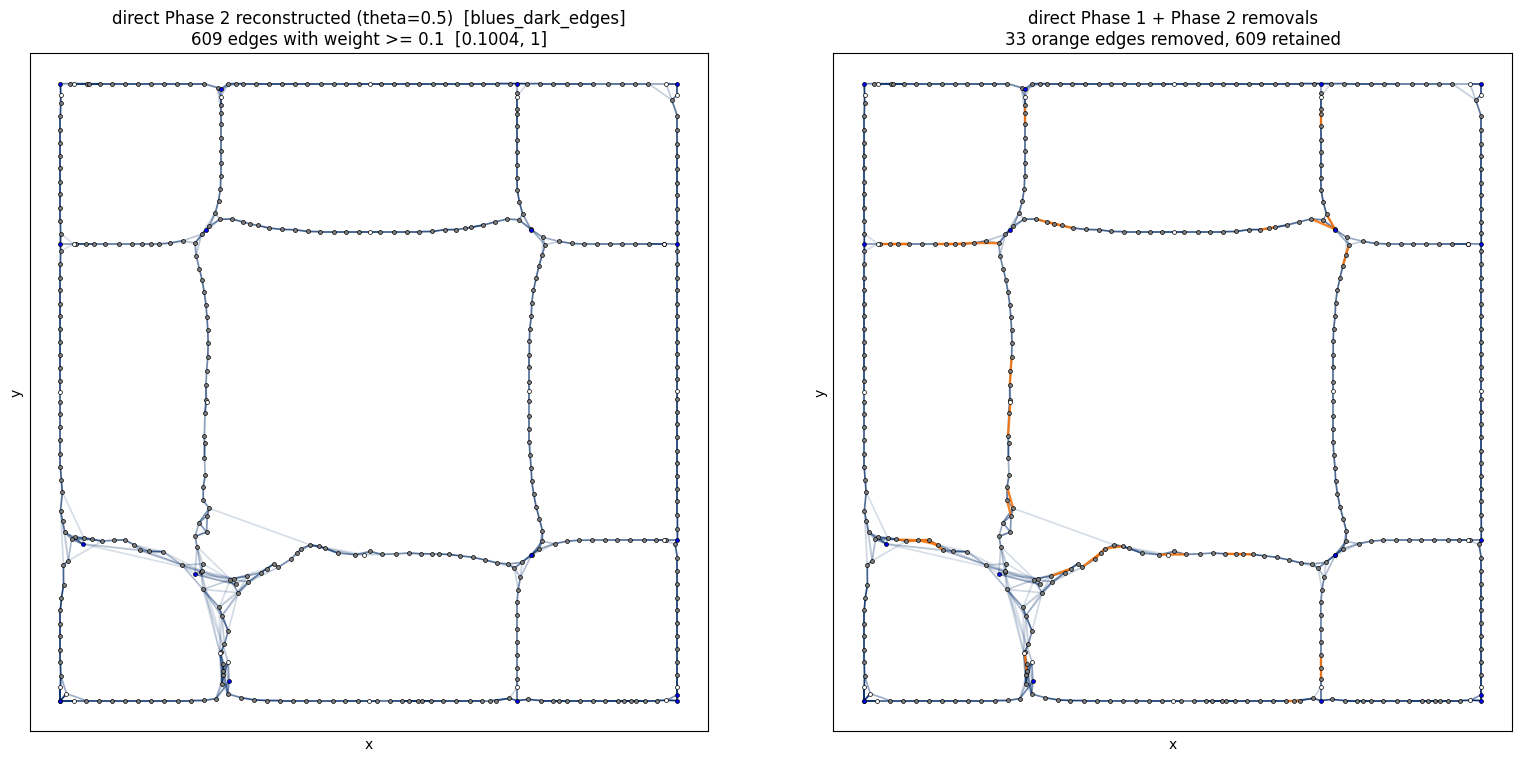

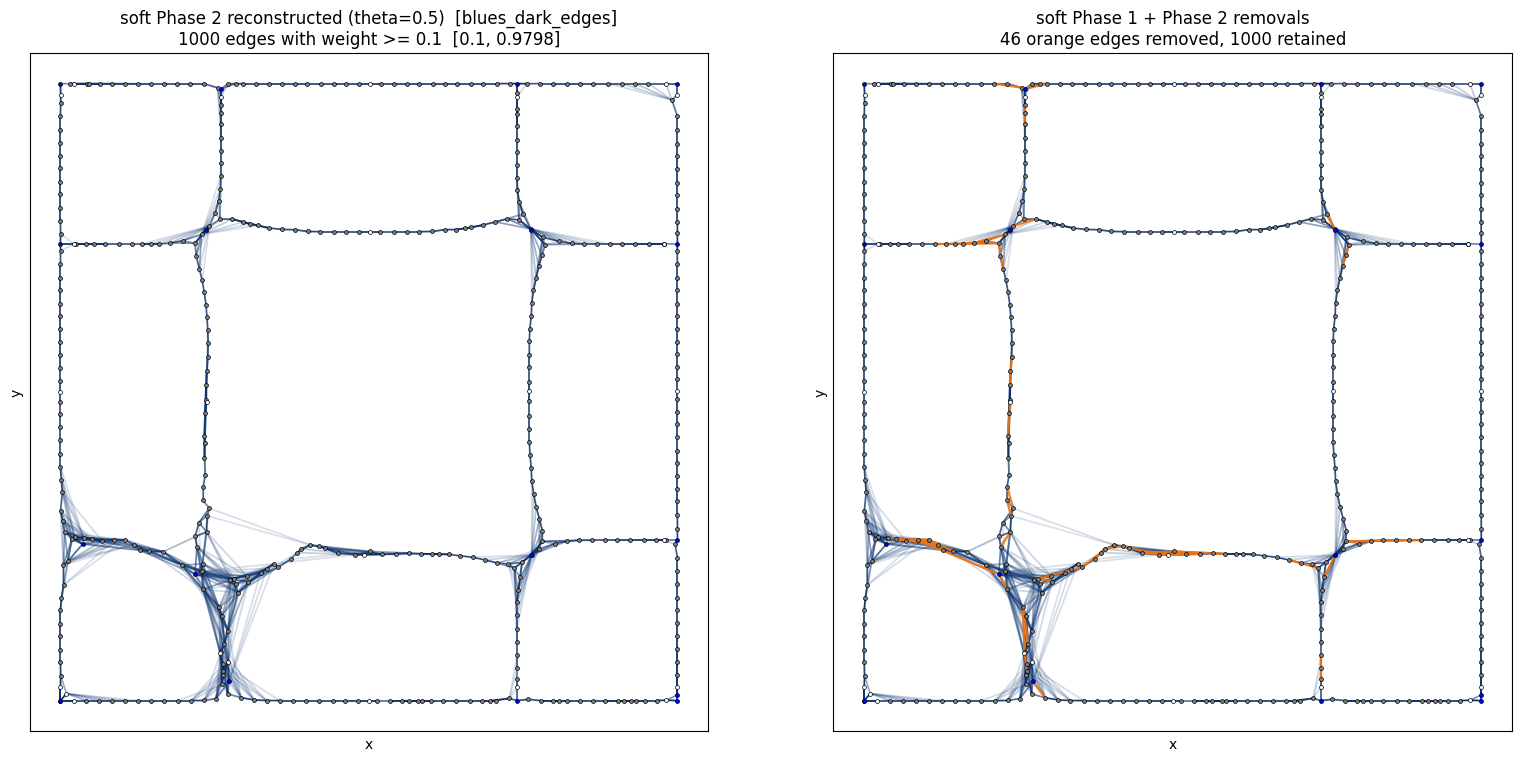

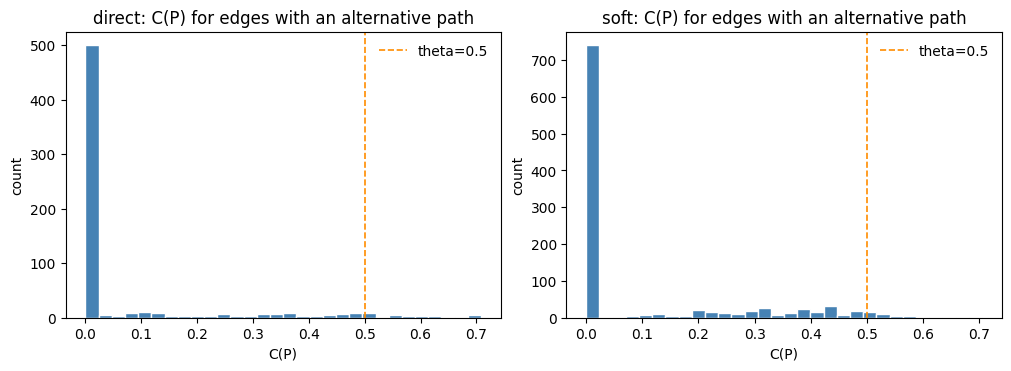

In [122]:
PHASE2_REMOVED_RGBA = (0.95, 0.45, 0.05, 0.90)


def draw_phase2_diagnostic(
    result,
    *,
    nodes_df,
    ax,
    min_transparency=MIN_TRANSPARENCY,
    retained_width=1.25,
    removed_width=1.7,
):
    pos = _barycenter_plot_positions(nodes_df)
    n = result.phase1_graph.number_of_nodes()
    if len(pos) != n:
        raise ValueError(f"Need finite (x, y) for all {n} nodes; got {len(pos)}.")

    blues = plt.get_cmap("Blues")
    cmap_obj = LinearSegmentedColormap.from_list(
        "blues_dark_edges", blues(np.linspace(0.99, 1.00, 256))
    )
    removed = {
        tuple(sorted((int(u), int(v))))
        for u, v in zip(
            result.removed_edges["u"].to_numpy() if len(result.removed_edges) else [],
            result.removed_edges["v"].to_numpy() if len(result.removed_edges) else [],
        )
    }
    retained_uv, retained_w, removed_segments = [], [], []
    for u, v, data in result.phase1_graph.edges(data=True):
        edge = tuple(sorted((int(u), int(v))))
        if edge in removed:
            removed_segments.append([pos[edge[0]], pos[edge[1]]])
        else:
            retained_uv.append(edge)
            retained_w.append(float(data.get("evidence", 0.0)))

    if retained_w:
        weights = np.asarray(retained_w, dtype=float)
        w_min = float(weights.min())
        w_max = float(weights.max())
        t = (
            np.ones(len(weights), dtype=float)
            if w_max <= w_min
            else (weights - w_min) / (w_max - w_min)
        )
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[:, 3] = min_transparency + (1.0 - min_transparency) * t
        ax.add_collection(
            LineCollection(
                [[pos[u], pos[v]] for u, v in retained_uv],
                colors=rgba,
                linewidths=retained_width,
                zorder=1,
            )
        )
    if removed_segments:
        ax.add_collection(
            LineCollection(
                removed_segments,
                colors=[PHASE2_REMOVED_RGBA],
                linewidths=removed_width,
                zorder=2,
            )
        )
    draw_msc_nodes(
        _msc_node_graph(nodes_df), pos, ax, regular_size=8, critical_size=8
    )
    set_barycenter_axes_limits(ax, pos)
    ax.set_title(
        f"{result.mode} Phase 1 + Phase 2 removals\n"
        f"{len(removed)} orange edges removed, {len(retained_uv)} retained"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")


def plot_phase2_reconstruction(result, *, nodes_df, figures_dir):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
    reconstructed_weights = evidence_matrix_from_graph(
        result.reconstructed_graph,
        n_nodes=result.phase1_graph.number_of_nodes(),
    )
    draw_barycenter_weighted_edges(
        reconstructed_weights,
        MIN_EDGE_THRESHOLD,
        MIN_TRANSPARENCY,
        nodes_df=nodes_df,
        title=f"{result.mode} Phase 2 reconstructed (theta={result.theta:g})",
        ax=axes[0],
    )
    draw_phase2_diagnostic(result, nodes_df=nodes_df, ax=axes[1])
    fig.savefig(figures_dir / f"phase2_reconstruction_{result.mode}.png", dpi=140)
    plt.show()
    return fig


plot_phase2_reconstruction(direct_phase2, nodes_df=nodes_df, figures_dir=FIGURES_DIR)
plot_phase2_reconstruction(soft_phase2, nodes_df=nodes_df, figures_dir=FIGURES_DIR)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, result in zip(axes, (direct_phase2, soft_phase2)):
    attempted = result.attempt_log
    if len(attempted) and "C" in attempted:
        values = attempted.loc[attempted["n_path_edges"] > 0, "C"].dropna()
        ax.hist(values.to_numpy(), bins=30, color="steelblue", edgecolor="white")
    ax.axvline(
        TRIANGLE_THETA, color="darkorange", ls="--", lw=1.2, label=f"theta={TRIANGLE_THETA}"
    )
    ax.set_title(f"{result.mode}: C(P) for edges with an alternative path")
    ax.set_xlabel("C(P)")
    ax.set_ylabel("count")
    ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "phase2_coherence_histograms.png", dpi=140)
plt.show()


### Phase 2 statistics and removal witnesses

Every Phase 2 removal stores the alternative path `P`, `C(P)`, per-input `C_i`, coverage weights, and the winning separatrix ID / direction. `beta_0` is asserted unchanged; `beta_1` should drop only when a same-separatrix cycle is deleted.


In [123]:
def _expand_phase2_removed(removed, n_inputs):
    if removed is None or len(removed) == 0:
        return pd.DataFrame()
    out = removed.copy().reset_index(drop=True)
    C = np.vstack(out["C_inputs"].to_numpy())
    W = np.vstack(out["weights"].to_numpy())
    sids = list(out["best_separatrix_ids"])
    dirs_ = list(out["best_directions"])
    scores = np.vstack(out["best_scores"].to_numpy())
    for i in range(int(n_inputs)):
        out[f"C_{i}"] = C[:, i]
        out[f"w_{i}"] = W[:, i]
        out[f"sid_{i}"] = [row[i] for row in sids]
        out[f"dir_{i}"] = [row[i] for row in dirs_]
        out[f"Csid_{i}"] = scores[:, i]
    out["path_str"] = out["path"].map(
        lambda p: "-".join(str(x) for x in p) if p is not None else ""
    )
    return out.drop(
        columns=["C_inputs", "weights", "best_separatrix_ids", "best_directions", "best_scores"]
    )


phase2_stats = pd.DataFrame(
    [
        {"mode": result.mode, "theta": result.theta, **result.statistics}
        for result in (direct_phase2, soft_phase2)
    ]
)
display(phase2_stats)

n_inputs = coherence_engine.n_inputs
direct_phase2_removed = _expand_phase2_removed(direct_phase2.removed_edges, n_inputs)
soft_phase2_removed = _expand_phase2_removed(soft_phase2.removed_edges, n_inputs)
direct_phase2_removed.to_csv(OUTPUT_DIR / "phase2_removed_edges_direct.csv", index=False)
soft_phase2_removed.to_csv(OUTPUT_DIR / "phase2_removed_edges_soft.csv", index=False)
display(Markdown("**Direct Phase 2 removals** (first rows)"))
display(direct_phase2_removed.head(12))
display(Markdown("**Soft Phase 2 removals** (first rows)"))
display(soft_phase2_removed.head(12))


,mode,theta,n_nodes,n_edges_before,n_removed,n_edges_after,beta_0_before,beta_0_after,beta_1_before,beta_1_after,n_alternative_paths,n_coherent_alternatives,removed_C_min,removed_C_median,removed_C_max,removed_path_edges_min,removed_path_edges_median,removed_path_edges_max
0,direct,0.5,427,642,33,609,1,1,216,183,642,33,0.503209,0.575735,0.708346,2,2.0,2
1,soft,0.5,427,1046,46,1000,1,1,620,574,1046,46,0.500031,0.526896,0.705038,2,2.0,4


**Direct Phase 2 removals** (first rows)

,u,v,evidence,decision,phase,n_path_edges,C,uninformative,weight_sum,path,...,w_7,sid_7,dir_7,Csid_7,C_8,w_8,sid_8,dir_8,Csid_8,path_str
0,65,316,0.100021,removed_same_separatrix_cycle,phase2,2,0.520793,False,9.000000,"[65, 63, 316]",...,1.000000,NaN,NaN,0.000000,0.643431,1.000000,35,reverse,0.643431,65-63-316
1,41,44,0.100548,removed_same_separatrix_cycle,phase2,2,0.561641,False,8.988346,"[41, 42, 44]",...,1.000000,NaN,NaN,0.000000,0.921768,1.000000,17,reverse,0.921768,41-42-44
2,52,55,0.114617,removed_same_separatrix_cycle,phase2,2,0.594936,False,8.728245,"[52, 53, 55]",...,1.000000,30,reverse,0.095247,0.016891,0.728245,33,forward,0.016891,52-53-55
3,37,38,0.127537,removed_same_separatrix_cycle,phase2,2,0.515512,False,8.354670,"[37, 50, 38]",...,1.000000,NaN,NaN,0.000000,0.871660,0.787650,32,forward,0.871660,37-50-38
4,33,35,0.142553,removed_same_separatrix_cycle,phase2,2,0.532779,False,9.000000,"[33, 34, 35]",...,1.000000,28,forward,0.786972,0.000000,1.000000,NaN,NaN,0.000000,33-34-35
5,193,205,0.143682,removed_same_separatrix_cycle,phase2,2,0.549436,False,9.000000,"[193, 194, 205]",...,1.000000,43,reverse,0.594888,0.269573,1.000000,39,reverse,0.269573,193-194-205
6,45,47,0.144844,removed_same_separatrix_cycle,phase2,2,0.513560,False,9.000000,"[45, 46, 47]",...,1.000000,23,reverse,0.161488,0.878890,1.000000,17,reverse,0.878890,45-46-47
7,70,72,0.153801,removed_same_separatrix_cycle,phase2,2,0.635384,False,9.000000,"[70, 71, 72]",...,1.000000,39,reverse,0.871449,0.000000,1.000000,NaN,NaN,0.000000,70-71-72
8,153,156,0.166683,removed_same_separatrix_cycle,phase2,2,0.671783,False,9.000000,"[153, 154, 156]",...,1.000000,35,reverse,0.888007,0.825915,1.000000,29,reverse,0.825915,153-154-156
9,11,13,0.166693,removed_same_separatrix_cycle,phase2,2,0.570728,False,8.639146,"[11, 12, 13]",...,1.000000,16,forward,0.946446,0.852308,1.000000,14,forward,0.852308,11-12-13


**Soft Phase 2 removals** (first rows)

,u,v,evidence,decision,phase,n_path_edges,C,uninformative,weight_sum,path,...,w_7,sid_7,dir_7,Csid_7,C_8,w_8,sid_8,dir_8,Csid_8,path_str
0,178,187,0.102313,removed_same_separatrix_cycle,phase2,4,0.547910,False,9.000000,"[178, 184, 185, 186, 187]",...,1.0,24,reverse,8.442882e-01,0.821886,1.000000,18,forward,0.821886,178-184-185-186-187
1,3,45,0.110038,removed_same_separatrix_cycle,phase2,3,0.520385,False,7.732025,"[3, 41, 44, 45]",...,1.0,NaN,NaN,0.000000e+00,0.944463,1.000000,17,reverse,0.944463,3-41-44-45
2,178,186,0.161597,removed_same_separatrix_cycle,phase2,3,0.524356,False,9.000000,"[178, 184, 185, 186]",...,1.0,24,reverse,8.653812e-01,0.840809,1.000000,18,forward,0.840809,178-184-185-186
3,5,11,0.266069,removed_same_separatrix_cycle,phase2,2,0.580042,False,8.639146,"[5, 9, 11]",...,1.0,NaN,NaN,0.000000e+00,1.000000,1.000000,14,forward,1.000000,5-9-11
4,3,19,0.293782,removed_same_separatrix_cycle,phase2,2,0.513554,False,7.732025,"[3, 28, 19]",...,1.0,15,reverse,1.000000e+00,0.434397,1.000000,9,forward,0.434397,3-28-19
5,274,278,0.320365,removed_same_separatrix_cycle,phase2,2,0.505766,False,9.000000,"[274, 275, 278]",...,1.0,NaN,NaN,0.000000e+00,0.909472,1.000000,20,reverse,0.909472,274-275-278
6,277,280,0.337699,removed_same_separatrix_cycle,phase2,2,0.500031,False,9.000000,"[277, 279, 280]",...,1.0,16,reverse,9.831445e-01,0.000000,1.000000,NaN,NaN,0.000000,277-279-280
7,24,49,0.340010,removed_same_separatrix_cycle,phase2,2,0.510043,False,7.593764,"[24, 408, 49]",...,1.0,NaN,NaN,0.000000e+00,1.000000,0.390104,9,forward,1.000000,24-408-49
8,42,409,0.345385,removed_same_separatrix_cycle,phase2,2,0.526531,False,9.000000,"[42, 45, 409]",...,1.0,23,reverse,6.487168e-09,0.819942,1.000000,17,reverse,0.819942,42-45-409
9,276,279,0.355567,removed_same_separatrix_cycle,phase2,2,0.521993,False,9.000000,"[276, 277, 279]",...,1.0,16,reverse,6.902069e-01,0.920015,1.000000,15,reverse,0.920015,276-277-279


### Phase 2 theta sensitivity

`C(P)` is independent of `theta`, but the greedy graph *is not*: an earlier removal changes later alternative paths. Each `theta` in `{0.4, 0.5, 0.6, 0.7}` therefore re-runs Phase 2 from the same Phase 1 graph. No value is selected as optimal.


In [124]:
phase2_sensitivity_rows = []
for phase1_result, mode in (
    (direct_triangle, "direct"),
    (soft_triangle, "soft"),
):
    for theta in THETA_SWEEP:
        swept = prune_same_separatrix_cycles(
            phase1_result.reconstructed_graph,
            coherence_engine,
            theta=theta,
            mode=mode,
        )
        phase2_sensitivity_rows.append(
            {
                "mode": mode,
                "theta": theta,
                "n_edges": swept.statistics["n_edges_after"],
                "n_removed": swept.statistics["n_removed"],
                "beta_0": swept.statistics["beta_0_after"],
                "beta_1": swept.statistics["beta_1_after"],
                "n_alternative_paths": swept.statistics["n_alternative_paths"],
                "n_coherent_alternatives": swept.statistics["n_coherent_alternatives"],
                "seconds": swept.elapsed_seconds,
            }
        )
phase2_theta_sensitivity = pd.DataFrame(phase2_sensitivity_rows)
display(phase2_theta_sensitivity)
phase2_theta_sensitivity.to_csv(
    OUTPUT_DIR / "phase2_theta_sensitivity.csv", index=False
)


,mode,theta,n_edges,n_removed,beta_0,beta_1,n_alternative_paths,n_coherent_alternatives,seconds
0,direct,0.4,586,56,1,160,642,56,0.338210
1,direct,0.5,609,33,1,183,642,33,0.277515
2,direct,0.6,629,13,1,203,642,13,0.279317
3,direct,0.7,638,4,1,212,642,4,0.492827
4,soft,0.4,929,117,1,503,1046,117,0.421169
5,soft,0.5,1000,46,1,574,1046,46,0.333227
6,soft,0.6,1039,7,1,613,1046,7,0.382819
7,soft,0.7,1044,2,1,618,1046,2,0.354468


### Phase 2 interpretation


In [125]:
def _phase2_line(result):
    s = result.statistics
    n_before = s["n_edges_before"]
    n_rem = s["n_removed"]
    frac = (n_rem / n_before) if n_before else 0.0
    return (
        f"- **{result.mode}:** {n_rem} / {n_before} Phase 1 edges pruned "
        f"({frac:.1%}), leaving {s['n_edges_after']} edges. "
        f"beta_0 {s['beta_0_before']} -> {s['beta_0_after']}, "
        f"beta_1 {s['beta_1_before']} -> {s['beta_1_after']}. "
        f"Alternative paths: {s['n_alternative_paths']}; "
        f"C(P)>=theta: {s['n_coherent_alternatives']}. "
        f"Removed C range [{s['removed_C_min']:.3f}, {s['removed_C_max']:.3f}] "
        f"(median {s['removed_C_median']:.3f}); "
        f"witness path edges median {s['removed_path_edges_median']}."
    )


def _theta_span(mode):
    sub = phase2_theta_sensitivity.loc[phase2_theta_sensitivity["mode"] == mode]
    return int(sub["n_removed"].min()), int(sub["n_removed"].max())


direct_lo, direct_hi = _theta_span("direct")
soft_lo, soft_hi = _theta_span("soft")
soft_before = soft_phase2.statistics["n_edges_before"]
theta_note = (
    "mild"
    if (soft_hi - soft_lo) <= 0.35 * max(soft_before, 1)
    else "noticeable"
)

display(Markdown(f"""
At `theta={TRIANGLE_THETA:g}` (same consensus parameter as Phase 1):

{_phase2_line(direct_phase2)}
{_phase2_line(soft_phase2)}

Phase 2 only deletes an edge when some alternative path is a **single** inferred 1-separatrix. Soft is again the interesting regime: remaining near-parallel bundles after Phase 1 are the expected same-separatrix cycles. Direct has fewer such duplicates.

**Loops.** `beta_0` is unchanged for both modes, so Phase 2 did not cut the graph into extra components. A drop in `beta_1` is the intended effect (same-separatrix cycle rank). Inspect the orange overlay on the soft Phase 1 graph, especially the lower-left bundle: duplicate tracks should thin while a loop whose two sides are *different* separatrices should survive.

**Theta.** Over {{0.4, 0.5, 0.6, 0.7}} Phase 2 removals span {direct_lo}-{direct_hi} (direct) and {soft_lo}-{soft_hi} (soft). That sensitivity is **{theta_note}**. `theta=0.5` is reported, not optimized.

**What this phase cannot do.** Remaining same-separatrix *branches*, dangling duplicates, or bundles that never form a cycle are out of scope. If a visually obvious bundle remains, the attempt log distinguishes: no alternative path, proposed `P` not coherent (`C(P) < theta`), or genuinely different separatrix IDs.

Branch-level pruning and geometric polishing are **not** implemented here.
"""))



At `theta=0.5` (same consensus parameter as Phase 1):

- **direct:** 33 / 642 Phase 1 edges pruned (5.1%), leaving 609 edges. beta_0 1 -> 1, beta_1 216 -> 183. Alternative paths: 642; C(P)>=theta: 33. Removed C range [0.503, 0.708] (median 0.576); witness path edges median 2.0.
- **soft:** 46 / 1046 Phase 1 edges pruned (4.4%), leaving 1000 edges. beta_0 1 -> 1, beta_1 620 -> 574. Alternative paths: 1046; C(P)>=theta: 46. Removed C range [0.500, 0.705] (median 0.527); witness path edges median 2.0.

Phase 2 only deletes an edge when some alternative path is a **single** inferred 1-separatrix. Soft is again the interesting regime: remaining near-parallel bundles after Phase 1 are the expected same-separatrix cycles. Direct has fewer such duplicates.

**Loops.** `beta_0` is unchanged for both modes, so Phase 2 did not cut the graph into extra components. A drop in `beta_1` is the intended effect (same-separatrix cycle rank). Inspect the orange overlay on the soft Phase 1 graph, especially the lower-left bundle: duplicate tracks should thin while a loop whose two sides are *different* separatrices should survive.

**Theta.** Over {0.4, 0.5, 0.6, 0.7} Phase 2 removals span 4-56 (direct) and 2-117 (soft). That sensitivity is **mild**. `theta=0.5` is reported, not optimized.

**What this phase cannot do.** Remaining same-separatrix *branches*, dangling duplicates, or bundles that never form a cycle are out of scope. If a visually obvious bundle remains, the attempt log distinguishes: no alternative path, proposed `P` not coherent (`C(P) < theta`), or genuinely different separatrix IDs.

Branch-level pruning and geometric polishing are **not** implemented here.


## Phase 2.1: widest same-separatrix-affinity pruning

This is a refinement of Phase 2, not a rewrite. Old Phase 2 results above are kept for comparison.

The remaining near-parallel bundles after Phase 2, especially in soft reconstruction, could be:

- **A.** redundant copies of one input 1-separatrix that `-log(evidence)` path search failed to propose as a long alternative, or
- **B.** genuine ensemble disagreement, because different inputs support different separatrix interpretations.

Phase 2.1 tests (A) with a length-neutral widest-path proposal on same-separatrix support, and requires the candidate edge and the replacement path to share the **same input separatrix ID and orientation**. Geometric bundling, MSTs-as-reconstruction, degree heuristics, and direct/soft blending remain out of scope.


### Part 0. Verify that Phase 1/2 separatrix scores are not input-adjacency tests

Soft evidence is allowed to support barycenter pairs whose coupled input locations are many hops apart on one recorded 1-separatrix. Phase 1 `input_between(i,x,y,z)` and Phase 2 `T_forward` / `T_reverse` must therefore **not** require `input_graph.has_edge(x,y)`.

Direct-mode edge support `S_direct` is different: it reuses the existing *direct evidence* criterion (adjacency **on that separatrix path**). Soft-mode `S_soft` uses the existing Gaussian kernel on all pairs along the same path.


In [126]:
import inspect
import time as _time

importlib.reload(msc_barycenter_reconstruction_separatrix)
from lib.msc_barycenter_reconstruction_separatrix import (
    classify_surviving_separatrix_support,
    count_thresholded_pairs,
    evidence_matrix_from_graph,
    input_nodes_between,
    input_nodes_between_from_positions,
    ordered_pair_support_along_path,
    prepare_edge_support_engine,
    prune_same_separatrix_redundancy,
    reconstruction_count_row,
    reconstruction_graph_statistics,
    run_phase21_tests,
    surviving_edge_support_table,
    widest_affinity_path,
    witness_path_length_stats,
    _directed_bilinear_support,
)


def _source_mentions_has_edge(fn):
    return "has_edge" in inspect.getsource(fn)


phase1_between_ok = (not _source_mentions_has_edge(input_nodes_between)) and (
    not _source_mentions_has_edge(input_nodes_between_from_positions)
)
phase2_T_ok = not _source_mentions_has_edge(ordered_pair_support_along_path)
bilinear_ok = not _source_mentions_has_edge(_directed_bilinear_support)

display(
    pd.Series(
        {
            "Phase1 input_between has no has_edge": phase1_between_ok,
            "Phase1 between-from-positions has no has_edge": not _source_mentions_has_edge(
                input_nodes_between_from_positions
            ),
            "Phase2 T_forward/T_reverse has no has_edge": phase2_T_ok,
            "bilinear S(u,v) has no has_edge": bilinear_ok,
        },
        name="verified",
    ).to_frame()
)

assert phase1_between_ok and phase2_T_ok and bilinear_ok, (
    "Bug: a Phase 1/2 separatrix predicate currently consults graph adjacency."
)

# Ordered-path construction of between_nodes uses left+2, so x and z need not be adjacent.
between_pair_hops = []
for index in betweenness_engine.path_indices:
    for sid, path in index.separatrix_paths.items():
        if len(path) >= 3:
            between_pair_hops.append(len(path) - 1)
print(
    "Input 1-separatrix path hops (min/median/max): "
    f"{min(between_pair_hops)} / {float(np.median(between_pair_hops)):.1f} / {max(between_pair_hops)}"
)
print(
    "Phase 1 between_nodes is existential over ordered positions on a simple path; "
    "x and z may be arbitrarily many hops apart."
)
print(
    "Phase 2 T_forward/T_reverse sums q_u(s_j) q_v(s_k) over j<k on that path; "
    "no input-graph edge is required."
)
print(
    "Direct S uses the path-adjacency kernel (same structural criterion as direct evidence). "
    "Soft S uses the existing Gaussian kernel on all pairs along the same path, including multi-hop pairs."
)

phase21_tests = run_phase21_tests()
assert all(phase21_tests.values()), phase21_tests
display(pd.Series(phase21_tests, name="passed").to_frame())


,verified
Phase1 input_between has no has_edge,True
Phase1 between-from-positions has no has_edge,True
Phase2 T_forward/T_reverse has no has_edge,True
"bilinear S(u,v) has no has_edge",True


Input 1-separatrix path hops (min/median/max): 2 / 12.0 / 21
Phase 1 between_nodes is existential over ordered positions on a simple path; x and z may be arbitrarily many hops apart.
Phase 2 T_forward/T_reverse sums q_u(s_j) q_v(s_k) over j<k on that path; no input-graph edge is required.
Direct S uses the path-adjacency kernel (same structural criterion as direct evidence). Soft S uses the existing Gaussian kernel on all pairs along the same path, including multi-hop pairs.


,passed
P0_no_input_adjacency_requirement,True
A_multihop_soft_not_direct,True
B_long_widest_path,True
C_same_separatrix_edge_and_path,True
D_different_separatrices,True
E_orientation,True
F_cross_input_uncertainty,True
G_partial_matching,True
H_bridge_protection,True
I_deterministic_and_chord,True


### Part 1. Count consistency with the plotted graphs

Printed edge counts must come from the **same graph object** that is converted to a weight matrix and passed to `draw_barycenter_weighted_edges`. Candidate / Phase 1 / old Phase 2 counts are reported here before any Phase 2.1 deletion.


In [127]:
def _assert_plot_count_matches(row, label):
    mismatches = []
    if row["candidate_edges"] != row["candidate_edges_thresholded_matrix"]:
        mismatches.append(
            f"candidate {row['candidate_edges']} vs matrix {row['candidate_edges_thresholded_matrix']}"
        )
    if row["phase1_edges"] != row["phase1_plot_matrix_edges"]:
        mismatches.append(
            f"phase1 {row['phase1_edges']} vs plot {row['phase1_plot_matrix_edges']}"
        )
    if row["phase2_edges"] != row["phase2_plot_matrix_edges"]:
        mismatches.append(
            f"phase2 {row['phase2_edges']} vs plot {row['phase2_plot_matrix_edges']}"
        )
    if mismatches:
        raise AssertionError(f"{label} plot/stat mismatch: " + "; ".join(mismatches))


phase12_count_rows = [
    reconstruction_count_row(
        mode="direct",
        candidate_graph=direct_triangle.candidate_graph,
        phase1=direct_triangle,
        phase2=direct_phase2,
        evidence_matrix=transported.direct_adjacency_evidence,
        threshold=MIN_EDGE_THRESHOLD,
    ),
    reconstruction_count_row(
        mode="soft",
        candidate_graph=soft_triangle.candidate_graph,
        phase1=soft_triangle,
        phase2=soft_phase2,
        evidence_matrix=transported.separatrix_connectivity_evidence,
        threshold=MIN_EDGE_THRESHOLD,
    ),
]
phase12_counts = pd.DataFrame(phase12_count_rows)
for row in phase12_count_rows:
    _assert_plot_count_matches(row, row["mode"])
display(Markdown("**Counts from the same objects later passed to plotting** (old Phase 2)."))
display(
    phase12_counts[
        [
            "mode",
            "candidate_edges",
            "phase1_edges",
            "phase2_edges",
            "phase1_removed",
            "phase2_removed",
        ]
    ]
)
print(
    "Plot-matrix recounts match graph.number_of_edges() at "
    f"MIN_EDGE_THRESHOLD={MIN_EDGE_THRESHOLD:g} for both modes."
)


**Counts from the same objects later passed to plotting** (old Phase 2).

,mode,candidate_edges,phase1_edges,phase2_edges,phase1_removed,phase2_removed
0,direct,757,642,609,115,33
1,soft,2720,1046,1000,1674,46


Plot-matrix recounts match graph.number_of_edges() at MIN_EDGE_THRESHOLD=0.1 for both modes.


### Parts 2-5. Per-edge same-separatrix support and surviving-soft audit

For barycenter edge $e=(u,v)$ and input $i$, $S_{i,s}(e)$ is the coupling mass that the $u$--$v$ connection is represented by input 1-separatrix $s$. Direct mode uses path adjacency on $s$. Soft mode uses the **same** Gaussian kernel already used for transported soft evidence, including non-adjacent positions on $s$.

$$
S_i(e)=\max_s S_{i,s}(e),\qquad
S_{\mathrm{sep}}(e)=\frac{\sum_i w_i(e)\,S_i(e)}{\sum_i w_i(e)},\qquad
w_i(e)=\min\bigl(r_i(u),r_i(v)\bigr).
$$

The max over $s$ is intentional: discrete input nodes can belong to several IDs, and summing would double-count. Separatrix IDs are local to each input and are **not** compared across graphs.


In [128]:
_t_support = _time.perf_counter()
support_engine = prepare_edge_support_engine(
    coherence_engine, bundle, transported, config
)
support_preprocess_seconds = _time.perf_counter() - _t_support
print(
    f"S_{{i,s}} preprocess: {support_engine.preprocess_seconds:.3f}s "
    f"(wrapper {support_preprocess_seconds:.3f}s); "
    f"sigma={support_engine.sigma:g}, length_scale={support_engine.length_scale:g}"
)

_t_audit = _time.perf_counter()
soft_phase2_support = surviving_edge_support_table(
    soft_phase2.reconstructed_graph,
    support_engine,
    "soft",
    theta=TRIANGLE_THETA,
    direct_evidence=transported.direct_adjacency_evidence,
)
soft_phase2_support_seconds = _time.perf_counter() - _t_audit
print(f"Old Phase 2 soft surviving-edge audit: {soft_phase2_support_seconds:.3f}s")

n_inputs = int(coherence_engine.n_inputs)
soft_phase2_support_csv = soft_phase2_support.copy()
S_stack = np.vstack(soft_phase2_support_csv["S_inputs"].to_numpy())
W_stack = np.vstack(soft_phase2_support_csv["weights"].to_numpy())
hop_stack = np.vstack(soft_phase2_support_csv["mean_hops"].to_numpy())
sids = list(soft_phase2_support_csv["best_separatrix_ids"])
dirs_ = list(soft_phase2_support_csv["best_directions"])
for i in range(n_inputs):
    soft_phase2_support_csv[f"S_{i}"] = S_stack[:, i]
    soft_phase2_support_csv[f"w_{i}"] = W_stack[:, i]
    soft_phase2_support_csv[f"sid_{i}"] = [row[i] for row in sids]
    soft_phase2_support_csv[f"dir_{i}"] = [row[i] for row in dirs_]
    soft_phase2_support_csv[f"hop_{i}"] = hop_stack[:, i]
soft_phase2_support_csv = soft_phase2_support_csv.drop(
    columns=["S_inputs", "weights", "best_separatrix_ids", "best_directions", "mean_hops"]
)
soft_phase2_support_csv.to_csv(OUTPUT_DIR / "phase2_surviving_soft_Ssep.csv", index=False)

ssep = soft_phase2_support["S_sep"].to_numpy(dtype=float)
strong = soft_phase2_support["strong_fraction"].to_numpy(dtype=float)
hops = soft_phase2_support["mean_hop"].to_numpy(dtype=float)
display(Markdown("**Old Phase 2 surviving soft edges: same-separatrix support**"))
display(
    pd.DataFrame(
        [
            {
                "n_edges": int(len(soft_phase2_support)),
                "S_sep_median": float(np.nanmedian(ssep)),
                "S_sep_mean": float(np.nanmean(ssep)),
                "S_sep_p10": float(np.nanpercentile(ssep, 10)),
                "S_sep_p90": float(np.nanpercentile(ssep, 90)),
                "frac_S_sep_ge_theta": float(np.mean(ssep >= TRIANGLE_THETA)),
                "strong_fraction_median": float(np.nanmedian(strong)),
                "S_std_median": float(np.nanmedian(soft_phase2_support["S_std"])),
                "mean_hop_median": float(np.nanmedian(hops)),
                "mean_hop_p90": float(np.nanpercentile(hops[np.isfinite(hops)], 90))
                if np.isfinite(hops).any()
                else float("nan"),
            }
        ]
    )
)
display(soft_phase2_support["category"].value_counts().rename("n_edges").to_frame())


S_{i,s} preprocess: 0.115s (wrapper 0.115s); sigma=0.05, length_scale=1.41421
Old Phase 2 soft surviving-edge audit: 0.516s


**Old Phase 2 surviving soft edges: same-separatrix support**

,n_edges,S_sep_median,S_sep_mean,S_sep_p10,S_sep_p90,frac_S_sep_ge_theta,strong_fraction_median,S_std_median,mean_hop_median,mean_hop_p90
0,1000,0.446896,0.498492,0.131863,0.932271,0.466,0.444444,0.180171,1.362108,4.238246


,n_edges
category,
low_separatrix,530
direct_like,396
high_consensus,73
mixed_uncertain,1


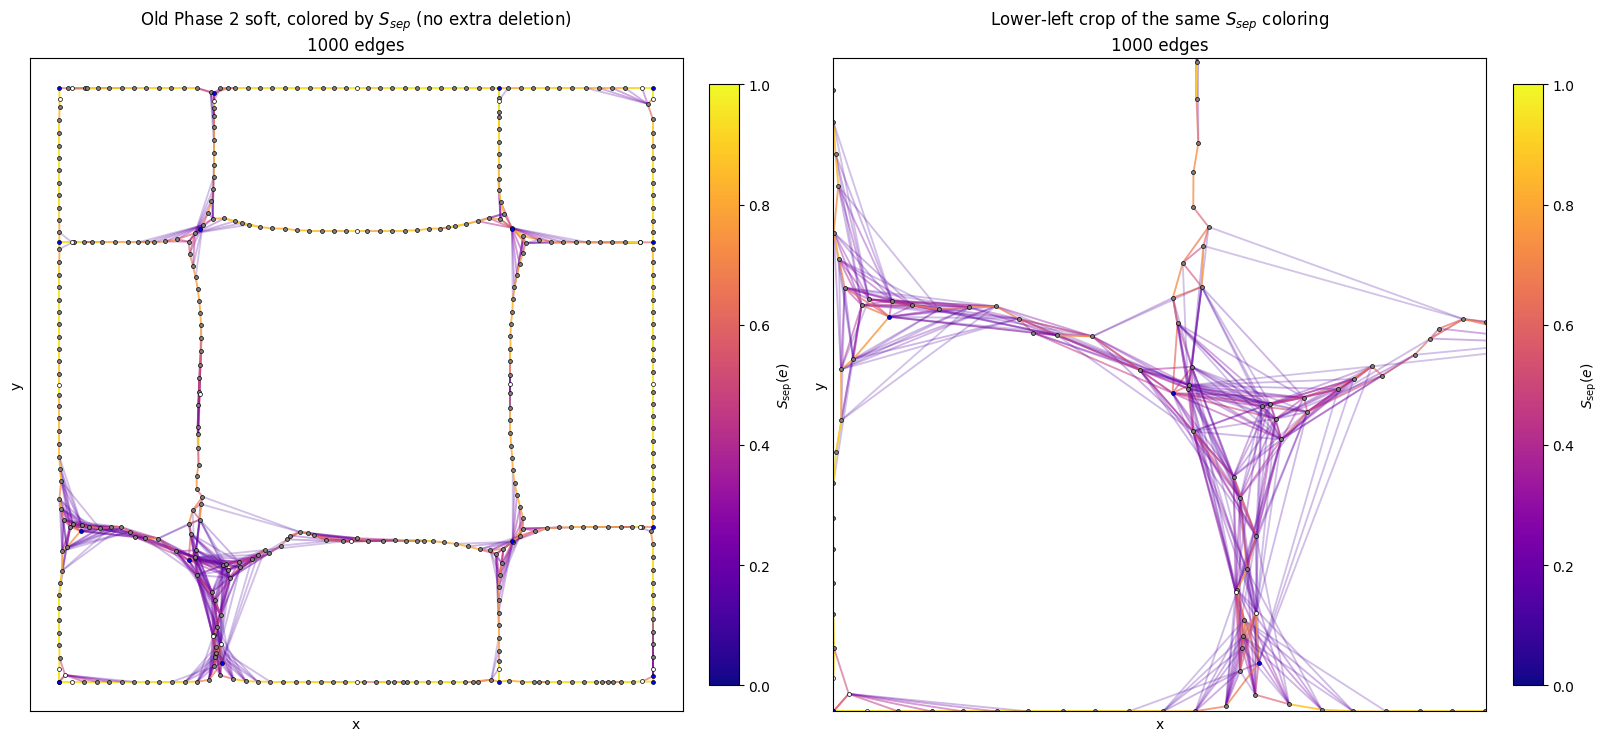

**Lower-left surviving old-Phase-2 soft edges** (diagnostic only; nothing removed).

,n_edges,S_sep_median,S_sep_mean,frac_S_sep_ge_theta,strong_fraction_median,S_std_median,mean_hop_median
0,437,0.24258,0.346588,0.24714,0.223279,0.266108,2.414628


,n_edges
category,
low_separatrix,329
direct_like,71
high_consensus,37


In [129]:
PHASE21_REMOVED_RGBA = (0.12, 0.55, 0.62, 0.92)
PHASE21_EXTRA_RGBA = (0.55, 0.18, 0.70, 0.90)


def _edge_set(frame):
    if frame is None or len(frame) == 0:
        return set()
    u_col = "u" if "u" in frame.columns else "a"
    v_col = "v" if "v" in frame.columns else "c"
    return {
        tuple(sorted((int(u), int(v))))
        for u, v in zip(frame[u_col].to_numpy(), frame[v_col].to_numpy())
    }


def draw_graph_colored_by_values(
    graph,
    value_map,
    *,
    nodes_df,
    ax,
    title,
    vmin=0.0,
    vmax=1.0,
    cmap_name="plasma",
    min_transparency=MIN_TRANSPARENCY,
    edge_width=1.35,
):
    pos = _barycenter_plot_positions(nodes_df)
    cmap_obj = plt.get_cmap(cmap_name)
    segments, colors = [], []
    values = []
    for u, v in graph.edges():
        key = tuple(sorted((int(u), int(v))))
        if key[0] not in pos or key[1] not in pos:
            continue
        val = float(value_map.get(key, 0.0))
        values.append(val)
        t = 0.0 if vmax <= vmin else float(np.clip((val - vmin) / (vmax - vmin), 0.0, 1.0))
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[3] = min_transparency + (1.0 - min_transparency) * t
        segments.append([pos[key[0]], pos[key[1]]])
        colors.append(rgba)
    if segments:
        ax.add_collection(
            LineCollection(segments, colors=colors, linewidths=edge_width, zorder=1)
        )
        norm = Normalize(vmin=vmin, vmax=vmax if vmax > vmin else vmin + 1e-12)
        mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        mappable.set_array([])
        cbar = ax.figure.colorbar(mappable, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(r"$S_{\mathrm{sep}}(e)$")
    draw_msc_nodes(_msc_node_graph(nodes_df), pos, ax, regular_size=8, critical_size=8)
    set_barycenter_axes_limits(ax, pos)
    ax.set_title(f"{title}\n{graph.number_of_edges()} edges")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    return values


def _lower_left_limits(nodes, frac=0.42):
    xs = nodes["x"].to_numpy(dtype=float)
    ys = nodes["y"].to_numpy(dtype=float)
    xmin, xmax = float(np.nanmin(xs)), float(np.nanmax(xs))
    ymin, ymax = float(np.nanmin(ys)), float(np.nanmax(ys))
    return (
        xmin,
        xmin + frac * (xmax - xmin),
        ymin,
        ymin + frac * (ymax - ymin),
    )


def _in_lower_left(u, v, pos, limits):
    x0, x1, y0, y1 = limits
    pu, pv = pos[int(u)], pos[int(v)]
    return (
        (x0 <= pu[0] <= x1 and y0 <= pu[1] <= y1)
        or (x0 <= pv[0] <= x1 and y0 <= pv[1] <= y1)
    )


soft_ssep_map = {
    tuple(sorted((int(u), int(v)))): float(s)
    for u, v, s in zip(
        soft_phase2_support["u"],
        soft_phase2_support["v"],
        soft_phase2_support["S_sep"],
    )
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
draw_graph_colored_by_values(
    soft_phase2.reconstructed_graph,
    soft_ssep_map,
    nodes_df=nodes_df,
    ax=axes[0],
    title="Old Phase 2 soft, colored by $S_{sep}$ (no extra deletion)",
)
pos = _barycenter_plot_positions(nodes_df)
ll = _lower_left_limits(nodes_df)
draw_graph_colored_by_values(
    soft_phase2.reconstructed_graph,
    soft_ssep_map,
    nodes_df=nodes_df,
    ax=axes[1],
    title="Lower-left crop of the same $S_{sep}$ coloring",
)
axes[1].set_xlim(ll[0], ll[1])
axes[1].set_ylim(ll[2], ll[3])
fig.savefig(FIGURES_DIR / "phase2_soft_surviving_Ssep.png", dpi=140)
plt.show()

ll_mask = [
    _in_lower_left(u, v, pos, ll)
    for u, v in zip(soft_phase2_support["u"], soft_phase2_support["v"])
]
ll_support = soft_phase2_support.loc[ll_mask]
display(Markdown("**Lower-left surviving old-Phase-2 soft edges** (diagnostic only; nothing removed)."))
if len(ll_support):
    display(
        pd.DataFrame(
            [
                {
                    "n_edges": int(len(ll_support)),
                    "S_sep_median": float(ll_support["S_sep"].median()),
                    "S_sep_mean": float(ll_support["S_sep"].mean()),
                    "frac_S_sep_ge_theta": float(
                        np.mean(ll_support["S_sep"] >= TRIANGLE_THETA)
                    ),
                    "strong_fraction_median": float(ll_support["strong_fraction"].median()),
                    "S_std_median": float(ll_support["S_std"].median()),
                    "mean_hop_median": float(np.nanmedian(ll_support["mean_hop"])),
                }
            ]
        )
    )
    display(ll_support["category"].value_counts().rename("n_edges").to_frame())
else:
    print("No old-Phase-2 soft edges intersect the lower-left crop.")


### Parts 6-11. Phase 2.1: widest $S_{\mathrm{sep}}$ path and $R(e,P)$

After temporarily deleting $e=(u,v)$, propose

$$
P^{\star}=\arg\max_P \min_{f\in P} A(f),\qquad A(f)=S_{\mathrm{sep}}(f).
$$

The bottleneck does not shrink with hop count. Remove $e$ only if the same input separatrix and orientation support **both** $e$ and $P^{\star}$:

$$
R_i(e,P)=\max_s \max\bigl(\min(S^{\rightarrow}_{i,s}(e),C^{\rightarrow}_{i,s}(P)),\min(S^{\leftarrow}_{i,s}(e),C^{\leftarrow}_{i,s}(P))\bigr),
$$

then $R(e,P)$ is the usual coverage-weighted mean with $w_i=\min_{v\in P} r_i(v)$. The consensus cutoff remains $\theta=0.5$. Direct and soft use this same loop; only the $S_{i,s}$ kernel differs. Greedy increasing-evidence order and bridge protection are unchanged. Phase 2.1 starts from the Phase 1 graphs, independently of old Phase 2.


In [130]:
_t_direct21 = _time.perf_counter()
direct_phase21 = prune_same_separatrix_redundancy(
    direct_triangle.reconstructed_graph,
    support_engine,
    "direct",
    theta=TRIANGLE_THETA,
)
direct_phase21_seconds = _time.perf_counter() - _t_direct21

_t_soft21 = _time.perf_counter()
soft_phase21 = prune_same_separatrix_redundancy(
    soft_triangle.reconstructed_graph,
    support_engine,
    "soft",
    theta=TRIANGLE_THETA,
)
soft_phase21_seconds = _time.perf_counter() - _t_soft21

print(
    f"Phase 2.1 timing: support_preprocess={support_engine.preprocess_seconds:.3f}s  "
    f"direct={direct_phase21_seconds:.3f}s  soft={soft_phase21_seconds:.3f}s"
)
assert (
    direct_phase21.statistics["beta_0_after"]
    == direct_phase21.statistics["beta_0_before"]
)
assert (
    soft_phase21.statistics["beta_0_after"]
    == soft_phase21.statistics["beta_0_before"]
)

phase21_count_rows = [
    reconstruction_count_row(
        mode="direct",
        candidate_graph=direct_triangle.candidate_graph,
        phase1=direct_triangle,
        phase2=direct_phase2,
        evidence_matrix=transported.direct_adjacency_evidence,
        threshold=MIN_EDGE_THRESHOLD,
        phase21=direct_phase21,
    ),
    reconstruction_count_row(
        mode="soft",
        candidate_graph=soft_triangle.candidate_graph,
        phase1=soft_triangle,
        phase2=soft_phase2,
        evidence_matrix=transported.separatrix_connectivity_evidence,
        threshold=MIN_EDGE_THRESHOLD,
        phase21=soft_phase21,
    ),
]
phase21_counts = pd.DataFrame(phase21_count_rows)
for row in phase21_count_rows:
    _assert_plot_count_matches(row, row["mode"])
    if row["phase21_edges"] != row["phase21_plot_matrix_edges"]:
        raise AssertionError(
            f"{row['mode']} Phase 2.1 plot mismatch: "
            f"{row['phase21_edges']} vs {row['phase21_plot_matrix_edges']}"
        )
display(Markdown("**Consistent reconstruction counts** (graph objects = plotted matrices)."))
display(
    phase21_counts[
        [
            "mode",
            "candidate_edges",
            "phase1_edges",
            "phase2_edges",
            "phase21_edges",
            "phase1_removed",
            "phase2_removed",
            "phase21_removed",
        ]
    ]
)


Phase 2.1 timing: support_preprocess=0.115s  direct=2.576s  soft=3.658s


**Consistent reconstruction counts** (graph objects = plotted matrices).

,mode,candidate_edges,phase1_edges,phase2_edges,phase21_edges,phase1_removed,phase2_removed,phase21_removed
0,direct,757,642,609,640,115,33,2
1,soft,2720,1046,1000,1041,1674,46,5


### Part 12. Old Phase 2 versus Phase 2.1

Old Phase 2 proposes an evidence-product path and tests $C(P)\ge\theta$. Phase 2.1 proposes a widest $S_{\mathrm{sep}}$ path and tests $R(e,P^{\star})\ge\theta$. Witness hop statistics are reported for **all proposed alternatives**, not only successful removals.


In [131]:
def _compare_row(phase2, phase21):
    proposed2 = witness_path_length_stats(phase2.attempt_log)
    removed2 = witness_path_length_stats(phase2.removed_edges)
    proposed21 = witness_path_length_stats(phase21.attempt_log)
    removed21 = witness_path_length_stats(phase21.removed_edges)
    old_rm = _edge_set(phase2.removed_edges)
    new_rm = _edge_set(phase21.removed_edges)
    return {
        "mode": phase2.mode,
        "phase1_edges": int(phase2.statistics["n_edges_before"]),
        "old_phase2_removed": int(phase2.statistics["n_removed"]),
        "phase21_removed": int(phase21.statistics["n_removed"]),
        "old_phase2_final_edges": int(phase2.statistics["n_edges_after"]),
        "phase21_final_edges": int(phase21.statistics["n_edges_after"]),
        "old_beta_0": int(phase2.statistics["beta_0_after"]),
        "phase21_beta_0": int(phase21.statistics["beta_0_after"]),
        "old_beta_1": int(phase2.statistics["beta_1_after"]),
        "phase21_beta_1": int(phase21.statistics["beta_1_after"]),
        "extra_phase21_not_in_old": int(len(new_rm - old_rm)),
        "old_not_in_phase21": int(len(old_rm - new_rm)),
        "shared_removals": int(len(old_rm & new_rm)),
        "old_proposed_median": proposed2["median"],
        "old_proposed_mean": proposed2["mean"],
        "old_proposed_max": proposed2["max"],
        "old_removed_median": removed2["median"],
        "old_removed_mean": removed2["mean"],
        "old_removed_max": removed2["max"],
        "phase21_proposed_median": proposed21["median"],
        "phase21_proposed_mean": proposed21["mean"],
        "phase21_proposed_max": proposed21["max"],
        "phase21_removed_median": removed21["median"],
        "phase21_removed_mean": removed21["mean"],
        "phase21_removed_max": removed21["max"],
    }


phase21_comparison = pd.DataFrame(
    [
        _compare_row(direct_phase2, direct_phase21),
        _compare_row(soft_phase2, soft_phase21),
    ]
)
display(phase21_comparison)
phase21_comparison.to_csv(OUTPUT_DIR / "phase21_vs_phase2_comparison.csv", index=False)

display(Markdown("**Direct Phase 2.1 statistics**"))
display(pd.DataFrame([{"mode": "direct", "theta": direct_phase21.theta, **direct_phase21.statistics}]))
display(Markdown("**Soft Phase 2.1 statistics**"))
display(pd.DataFrame([{"mode": "soft", "theta": soft_phase21.theta, **soft_phase21.statistics}]))

if float(phase21_comparison.loc[phase21_comparison["mode"] == "soft", "phase21_proposed_median"].iloc[0]) <= 3:
    print(
        "Soft Phase 2.1 proposed paths are still mostly short. "
        "Inspect attempt_log hop histograms: if proposals are long but R is low, "
        "the widest-path search is working and same-separatrix redundancy is the limiter. "
        "If proposals themselves stay at 2-3 hops, bottleneck affinities of long tracks are weak."
    )


,mode,phase1_edges,old_phase2_removed,phase21_removed,old_phase2_final_edges,phase21_final_edges,old_beta_0,phase21_beta_0,old_beta_1,phase21_beta_1,...,old_proposed_max,old_removed_median,old_removed_mean,old_removed_max,phase21_proposed_median,phase21_proposed_mean,phase21_proposed_max,phase21_removed_median,phase21_removed_mean,phase21_removed_max
0,direct,642,33,2,609,640,1,1,183,214,...,194,2.0,2.000000,2,73.0,76.699377,201,2.0,2.0,2
1,soft,1046,46,5,1000,1041,1,1,574,615,...,70,2.0,2.086957,4,6.0,54.179732,163,2.0,2.0,2


**Direct Phase 2.1 statistics**

,mode,theta,n_nodes,n_edges_before,n_removed,n_edges_after,beta_0_before,beta_0_after,beta_1_before,beta_1_after,n_alternative_paths,n_redundant_alternatives,removed_R_min,removed_R_median,removed_R_max,removed_path_edges_min,removed_path_edges_median,removed_path_edges_mean,removed_path_edges_max
0,direct,0.5,427,642,2,640,1,1,216,214,642,2,0.502711,0.505738,0.508764,2,2.0,2.0,2


**Soft Phase 2.1 statistics**

,mode,theta,n_nodes,n_edges_before,n_removed,n_edges_after,beta_0_before,beta_0_after,beta_1_before,beta_1_after,n_alternative_paths,n_redundant_alternatives,removed_R_min,removed_R_median,removed_R_max,removed_path_edges_min,removed_path_edges_median,removed_path_edges_mean,removed_path_edges_max
0,soft,0.5,427,1046,5,1041,1,1,620,615,1046,5,0.515551,0.526614,0.563773,2,2.0,2.0,2


### Parts 13-15. Surviving-edge classification, plots, and removal metadata

Surviving soft Phase 2.1 edges are labeled diagnostically. Thresholds reuse existing $\theta=0.5$ and are **not** extra deletion rules.

- `direct_like`: direct evidence also $\ge\theta$
- `high_consensus`: high $S_{\mathrm{sep}}$ and strong per-input consistency, but no adequate same-separatrix replacement
- `mixed_uncertain`: moderate aggregate support or cross-input variability
- `low_separatrix`: the edge is not consistently one input 1-separatrix


In [132]:
soft_phase21_support = surviving_edge_support_table(
    soft_phase21.reconstructed_graph,
    support_engine,
    "soft",
    theta=TRIANGLE_THETA,
    direct_evidence=transported.direct_adjacency_evidence,
)
soft_phase21_support_csv = soft_phase21_support.copy()
S_stack = np.vstack(soft_phase21_support_csv["S_inputs"].to_numpy()) if len(soft_phase21_support_csv) else np.zeros((0, n_inputs))
W_stack = np.vstack(soft_phase21_support_csv["weights"].to_numpy()) if len(soft_phase21_support_csv) else np.zeros((0, n_inputs))
hop_stack = np.vstack(soft_phase21_support_csv["mean_hops"].to_numpy()) if len(soft_phase21_support_csv) else np.zeros((0, n_inputs))
sids = list(soft_phase21_support_csv["best_separatrix_ids"]) if len(soft_phase21_support_csv) else []
dirs_ = list(soft_phase21_support_csv["best_directions"]) if len(soft_phase21_support_csv) else []
for i in range(n_inputs):
    if len(soft_phase21_support_csv):
        soft_phase21_support_csv[f"S_{i}"] = S_stack[:, i]
        soft_phase21_support_csv[f"w_{i}"] = W_stack[:, i]
        soft_phase21_support_csv[f"sid_{i}"] = [row[i] for row in sids]
        soft_phase21_support_csv[f"dir_{i}"] = [row[i] for row in dirs_]
        soft_phase21_support_csv[f"hop_{i}"] = hop_stack[:, i]
soft_phase21_support_csv = soft_phase21_support_csv.drop(
    columns=["S_inputs", "weights", "best_separatrix_ids", "best_directions", "mean_hops"],
    errors="ignore",
)
soft_phase21_support_csv.to_csv(OUTPUT_DIR / "phase21_surviving_soft_Ssep.csv", index=False)

display(Markdown("**Phase 2.1 surviving soft classification** (diagnostic labels only)."))
if len(soft_phase21_support):
    display(soft_phase21_support["category"].value_counts().rename("n_edges").to_frame())
    display(
        soft_phase21_support.groupby("category")[["evidence", "S_sep", "strong_fraction", "S_std", "mean_hop"]]
        .median()
        .reset_index()
    )
else:
    print("No surviving soft Phase 2.1 edges.")


def _expand_phase21_removed(removed, n_inputs):
    if removed is None or len(removed) == 0:
        return pd.DataFrame()
    out = removed.copy().reset_index(drop=True)
    R = np.vstack(out["R_inputs"].to_numpy())
    W = np.vstack(out["weights"].to_numpy())
    S = np.vstack(out["S_matched"].to_numpy())
    C = np.vstack(out["C_matched"].to_numpy())
    sids = list(out["best_separatrix_ids"])
    dirs_ = list(out["best_directions"])
    for i in range(int(n_inputs)):
        out[f"R_{i}"] = R[:, i]
        out[f"w_{i}"] = W[:, i]
        out[f"S_{i}"] = S[:, i]
        out[f"C_{i}"] = C[:, i]
        out[f"sid_{i}"] = [row[i] for row in sids]
        out[f"dir_{i}"] = [row[i] for row in dirs_]
    out["path_str"] = out["path"].map(
        lambda p: "-".join(str(x) for x in p) if p is not None else ""
    )
    return out.drop(
        columns=["R_inputs", "weights", "S_matched", "C_matched", "best_separatrix_ids", "best_directions"]
    )


direct_phase21_removed = _expand_phase21_removed(direct_phase21.removed_edges, n_inputs)
soft_phase21_removed = _expand_phase21_removed(soft_phase21.removed_edges, n_inputs)
direct_phase21_removed.to_csv(OUTPUT_DIR / "phase21_removed_edges_direct.csv", index=False)
soft_phase21_removed.to_csv(OUTPUT_DIR / "phase21_removed_edges_soft.csv", index=False)
display(Markdown("**Direct Phase 2.1 removals** (first rows)"))
display(direct_phase21_removed.head(12))
display(Markdown("**Soft Phase 2.1 removals** (first rows)"))
display(soft_phase21_removed.head(12))


**Phase 2.1 surviving soft classification** (diagnostic labels only).

,n_edges
category,
low_separatrix,549
direct_like,396
high_consensus,94
mixed_uncertain,2


,category,evidence,S_sep,strong_fraction,S_std,mean_hop
0,direct_like,0.850687,0.855280,1.000000,0.067044,1.065989
1,high_consensus,0.604530,0.615803,0.681281,0.284459,1.678162
2,low_separatrix,0.209767,0.210960,0.131687,0.238209,2.777120
3,mixed_uncertain,0.433377,0.531860,0.433804,0.225444,2.691536


**Direct Phase 2.1 removals** (first rows)

,u,v,evidence,S_sep,decision,phase,n_path_edges,R,uninformative,weight_sum,...,C_7,sid_7,dir_7,R_8,w_8,S_8,C_8,sid_8,dir_8,path_str
0,66,67,0.612229,0.612229,removed_same_separatrix_redundancy,phase2.1,2,0.502711,False,9.0,...,0.545709,39,reverse,0.471607,1.0,0.471607,0.684563,35,forward,66-419-67
1,330,331,0.697917,0.697917,removed_same_separatrix_redundancy,phase2.1,2,0.508764,False,9.0,...,0.695909,42,forward,0.559201,1.0,0.795126,0.559201,38,forward,330-400-331


**Soft Phase 2.1 removals** (first rows)

,u,v,evidence,S_sep,decision,phase,n_path_edges,R,uninformative,weight_sum,...,C_7,sid_7,dir_7,R_8,w_8,S_8,C_8,sid_8,dir_8,path_str
0,65,317,0.515551,0.515551,removed_same_separatrix_redundancy,phase2.1,2,0.515551,False,9.000000,...,2.793430e-01,39,forward,0.730101,1.000000,0.730101,0.851764,35,reverse,65-63-317
1,52,55,0.553900,0.571145,removed_same_separatrix_redundancy,phase2.1,2,0.563773,False,8.728245,...,9.524664e-02,30,reverse,0.002770,0.728245,0.002770,0.016891,33,forward,52-53-55
2,64,316,0.576608,0.576608,removed_same_separatrix_redundancy,phase2.1,2,0.547065,False,9.000000,...,8.484363e-01,31,reverse,0.236092,1.000000,0.236092,0.335285,33,forward,64-61-316
3,11,13,0.633365,0.659820,removed_same_separatrix_redundancy,phase2.1,2,0.526614,False,8.639146,...,9.464462e-01,16,forward,0.852308,1.000000,0.902577,0.852308,14,forward,11-12-13
4,42,45,0.655030,0.655030,removed_same_separatrix_redundancy,phase2.1,2,0.523597,False,9.000000,...,3.162278e-08,26,reverse,0.850799,1.000000,0.860148,0.850799,17,reverse,42-44-45


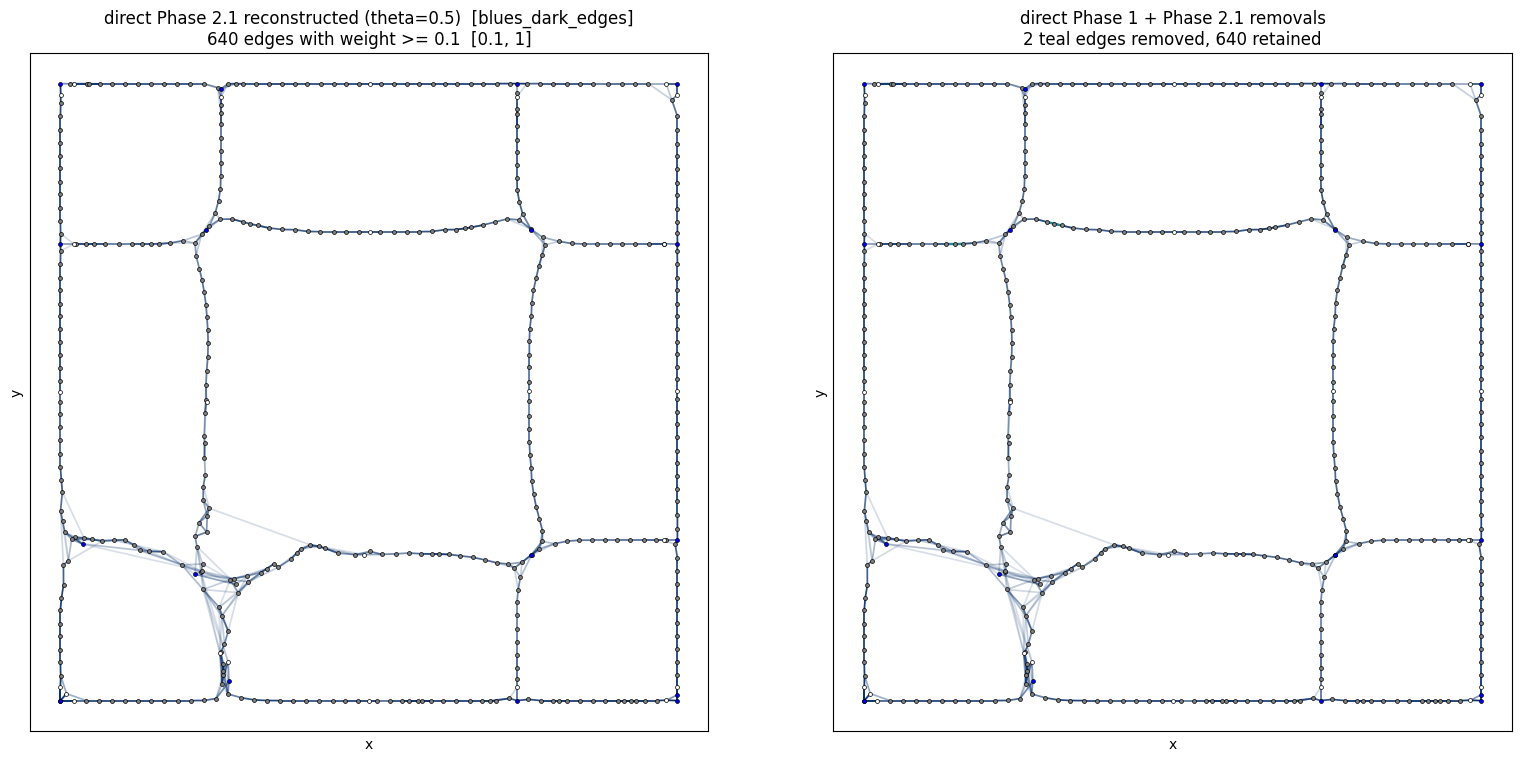

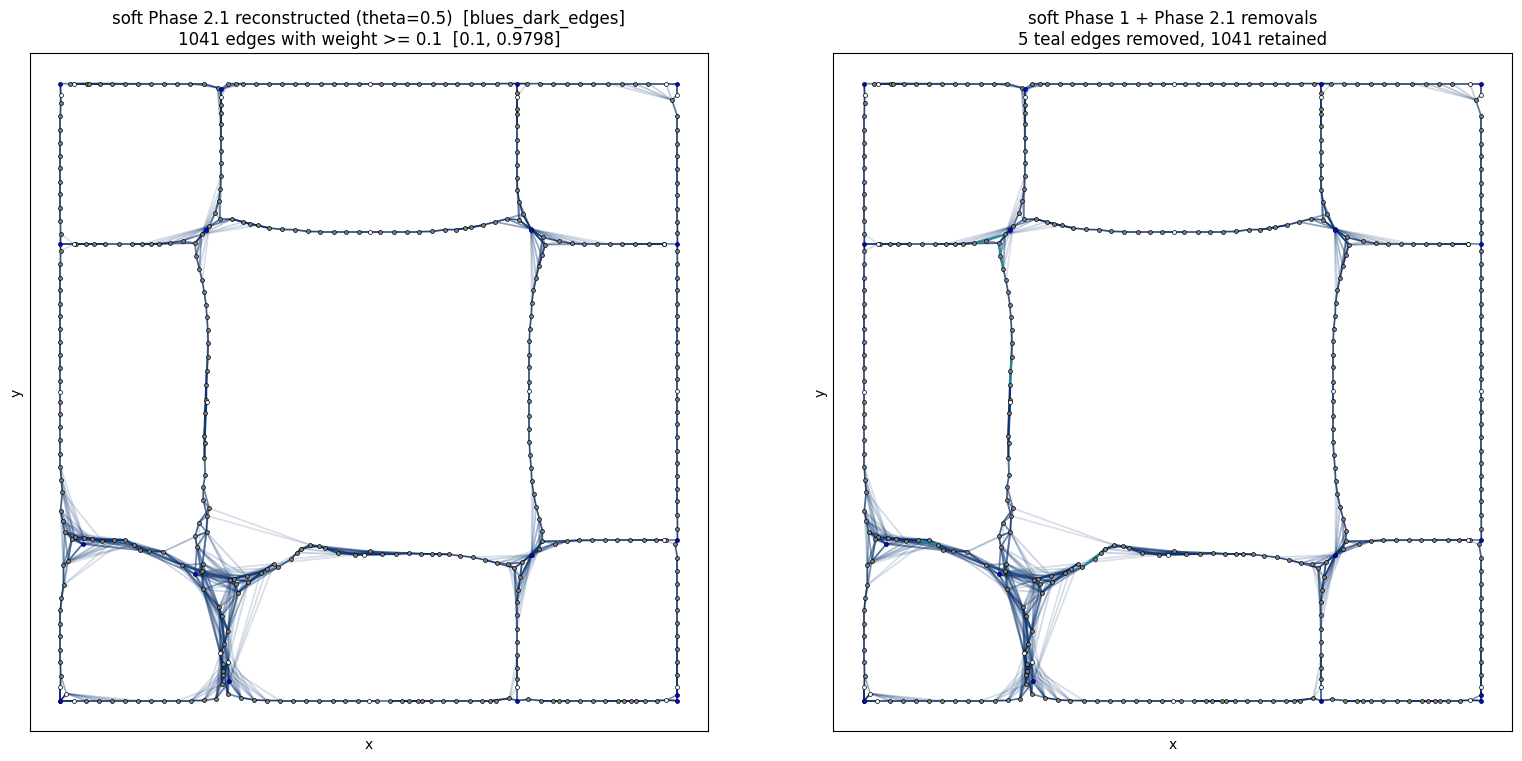

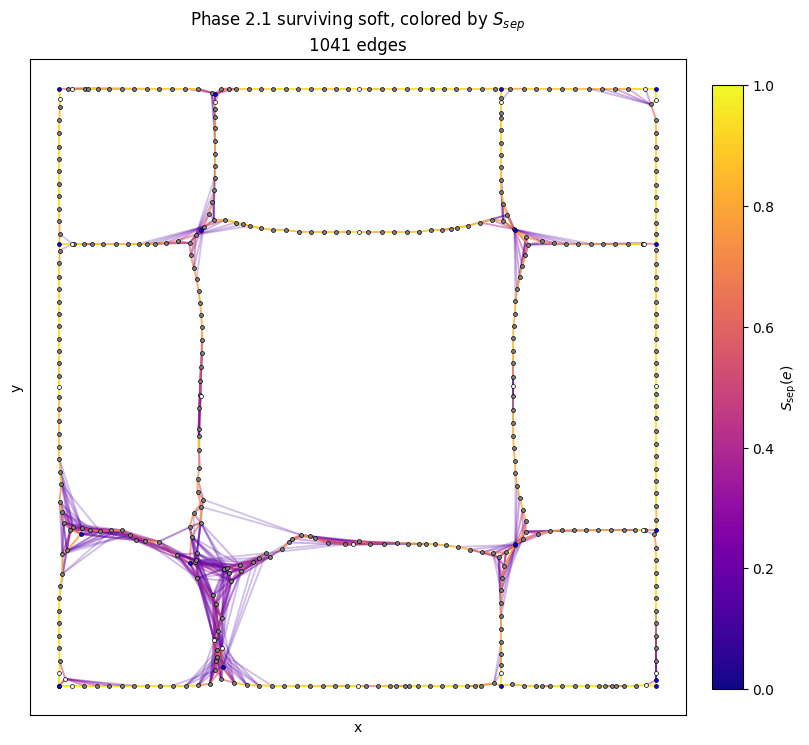

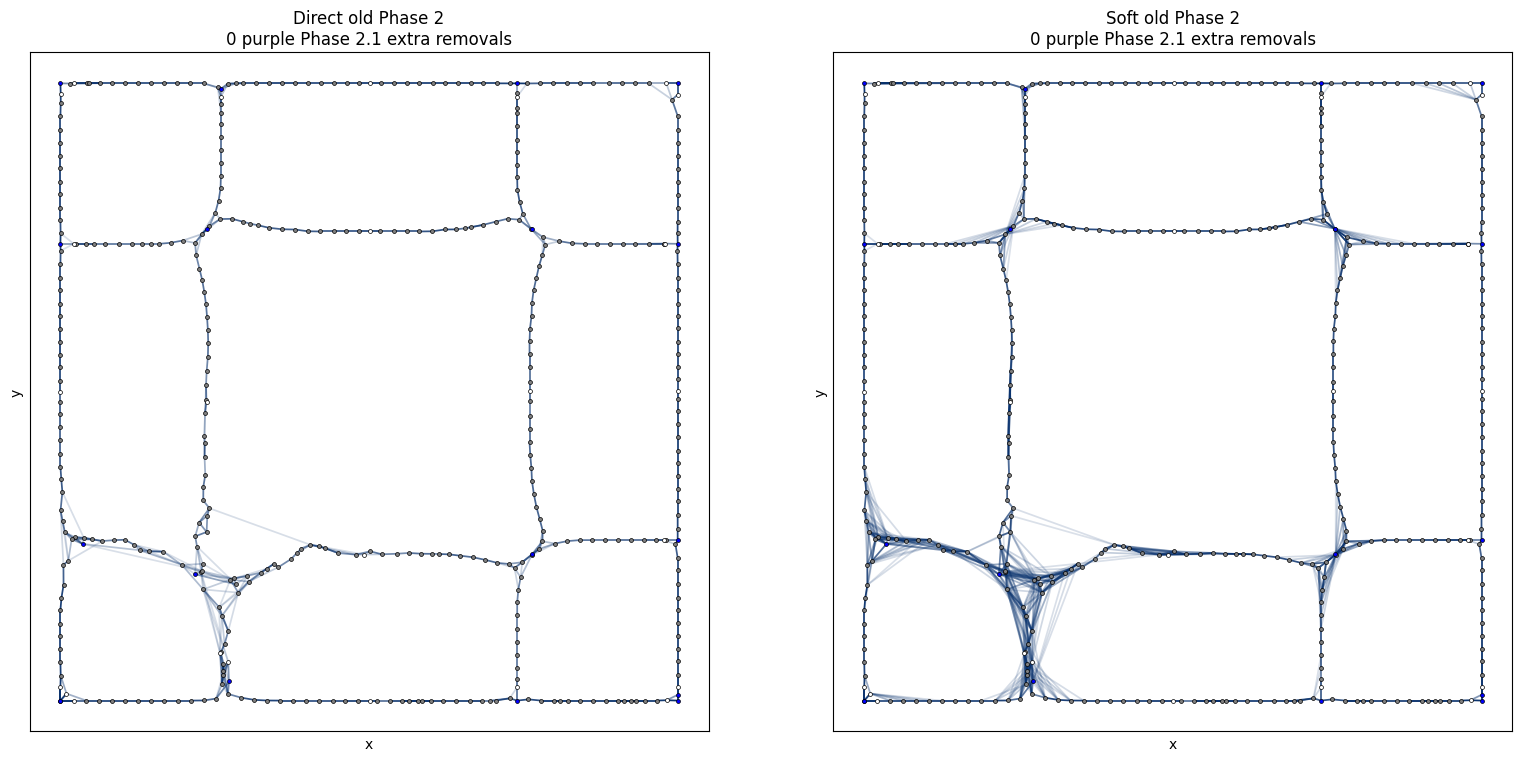

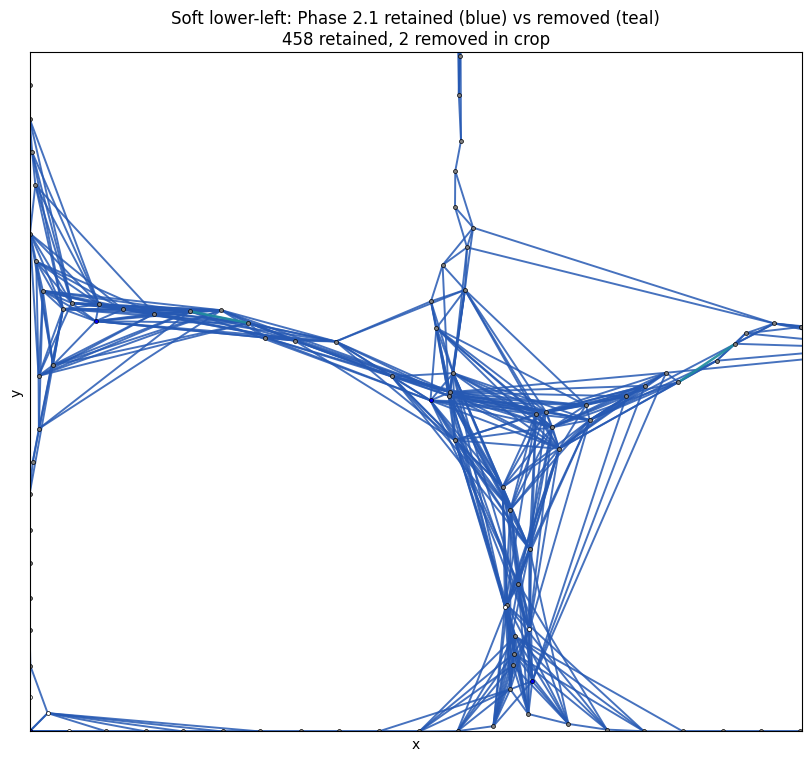

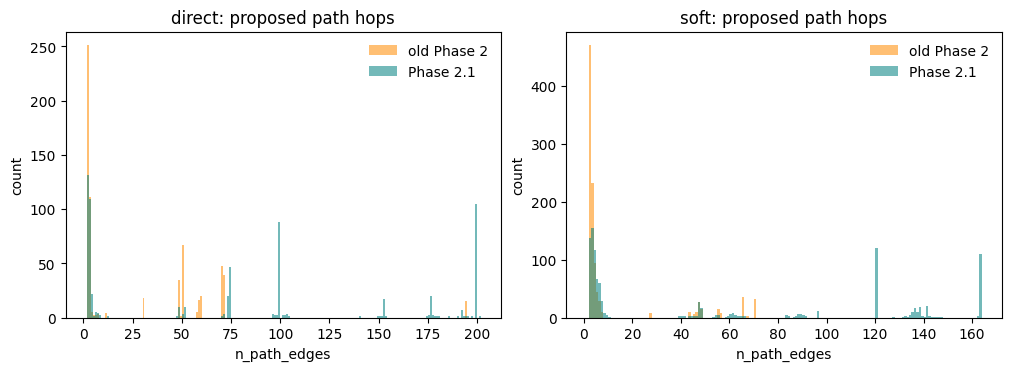

In [133]:
def draw_phase21_diagnostic(
    result,
    *,
    nodes_df,
    ax,
    removed_rgba=PHASE21_REMOVED_RGBA,
    min_transparency=MIN_TRANSPARENCY,
    retained_width=1.25,
    removed_width=1.7,
    title=None,
):
    pos = _barycenter_plot_positions(nodes_df)
    blues = plt.get_cmap("Blues")
    cmap_obj = LinearSegmentedColormap.from_list(
        "blues_dark_edges", blues(np.linspace(0.99, 1.00, 256))
    )
    removed = _edge_set(result.removed_edges)
    retained_uv, retained_w, removed_segments = [], [], []
    for u, v, data in result.phase1_graph.edges(data=True):
        edge = tuple(sorted((int(u), int(v))))
        if edge in removed:
            removed_segments.append([pos[edge[0]], pos[edge[1]]])
        else:
            retained_uv.append(edge)
            retained_w.append(float(data.get("evidence", 0.0)))
    if retained_w:
        weights = np.asarray(retained_w, dtype=float)
        w_min = float(weights.min())
        w_max = float(weights.max())
        t = (
            np.ones(len(weights), dtype=float)
            if w_max <= w_min
            else (weights - w_min) / (w_max - w_min)
        )
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[:, 3] = min_transparency + (1.0 - min_transparency) * t
        ax.add_collection(
            LineCollection(
                [[pos[u], pos[v]] for u, v in retained_uv],
                colors=rgba,
                linewidths=retained_width,
                zorder=1,
            )
        )
    if removed_segments:
        ax.add_collection(
            LineCollection(
                removed_segments,
                colors=[removed_rgba],
                linewidths=removed_width,
                zorder=2,
            )
        )
    draw_msc_nodes(_msc_node_graph(nodes_df), pos, ax, regular_size=8, critical_size=8)
    set_barycenter_axes_limits(ax, pos)
    ax.set_title(
        title
        or (
            f"{result.mode} Phase 1 + Phase 2.1 removals\n"
            f"{len(removed)} teal edges removed, {len(retained_uv)} retained"
        )
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")


def plot_phase21_reconstruction(result, *, nodes_df, figures_dir):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
    reconstructed_weights = evidence_matrix_from_graph(
        result.reconstructed_graph,
        n_nodes=result.phase1_graph.number_of_nodes(),
    )
    plotted = draw_barycenter_weighted_edges(
        reconstructed_weights,
        MIN_EDGE_THRESHOLD,
        MIN_TRANSPARENCY,
        nodes_df=nodes_df,
        title=f"{result.mode} Phase 2.1 reconstructed (theta={result.theta:g})",
        ax=axes[0],
    )
    if plotted["edge_count"] != result.reconstructed_graph.number_of_edges():
        raise AssertionError(
            f"{result.mode} Phase 2.1 plot {plotted['edge_count']} "
            f"!= graph {result.reconstructed_graph.number_of_edges()}"
        )
    draw_phase21_diagnostic(result, nodes_df=nodes_df, ax=axes[1])
    fig.savefig(figures_dir / f"phase21_reconstruction_{result.mode}.png", dpi=140)
    plt.show()
    return fig


plot_phase21_reconstruction(direct_phase21, nodes_df=nodes_df, figures_dir=FIGURES_DIR)
plot_phase21_reconstruction(soft_phase21, nodes_df=nodes_df, figures_dir=FIGURES_DIR)

soft_phase21_ssep_map = {
    tuple(sorted((int(u), int(v)))): float(s)
    for u, v, s in zip(
        soft_phase21_support["u"],
        soft_phase21_support["v"],
        soft_phase21_support["S_sep"],
    )
} if len(soft_phase21_support) else {}

fig, ax = plt.subplots(figsize=(8, 7.5), layout="constrained")
draw_graph_colored_by_values(
    soft_phase21.reconstructed_graph,
    soft_phase21_ssep_map,
    nodes_df=nodes_df,
    ax=ax,
    title="Phase 2.1 surviving soft, colored by $S_{sep}$",
)
fig.savefig(FIGURES_DIR / "phase21_soft_surviving_Ssep.png", dpi=140)
plt.show()

# Old Phase 2 graph with Phase 2.1 *additional* removals highlighted.
extra_soft = _edge_set(soft_phase21.removed_edges) - _edge_set(soft_phase2.removed_edges)
extra_direct = _edge_set(direct_phase21.removed_edges) - _edge_set(direct_phase2.removed_edges)


def draw_old_phase2_with_extra(phase2, extra, *, nodes_df, ax, title):
    pos = _barycenter_plot_positions(nodes_df)
    blues = plt.get_cmap("Blues")
    cmap_obj = LinearSegmentedColormap.from_list(
        "blues_dark_edges", blues(np.linspace(0.99, 1.00, 256))
    )
    retained_uv, retained_w, extra_segments = [], [], []
    for u, v, data in phase2.reconstructed_graph.edges(data=True):
        edge = tuple(sorted((int(u), int(v))))
        if edge in extra:
            extra_segments.append([pos[edge[0]], pos[edge[1]]])
        else:
            retained_uv.append(edge)
            retained_w.append(float(data.get("evidence", 0.0)))
    if retained_w:
        weights = np.asarray(retained_w, dtype=float)
        w_min, w_max = float(weights.min()), float(weights.max())
        t = np.ones(len(weights)) if w_max <= w_min else (weights - w_min) / (w_max - w_min)
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[:, 3] = MIN_TRANSPARENCY + (1.0 - MIN_TRANSPARENCY) * t
        ax.add_collection(
            LineCollection(
                [[pos[u], pos[v]] for u, v in retained_uv],
                colors=rgba,
                linewidths=1.25,
                zorder=1,
            )
        )
    if extra_segments:
        ax.add_collection(
            LineCollection(
                extra_segments,
                colors=[PHASE21_EXTRA_RGBA],
                linewidths=1.8,
                zorder=2,
            )
        )
    draw_msc_nodes(_msc_node_graph(nodes_df), pos, ax, regular_size=8, critical_size=8)
    set_barycenter_axes_limits(ax, pos)
    ax.set_title(f"{title}\n{len(extra_segments)} purple Phase 2.1 extra removals")
    ax.set_xlabel("x")
    ax.set_ylabel("y")


fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), layout="constrained")
draw_old_phase2_with_extra(
    direct_phase2, extra_direct, nodes_df=nodes_df, ax=axes[0], title="Direct old Phase 2"
)
draw_old_phase2_with_extra(
    soft_phase2, extra_soft, nodes_df=nodes_df, ax=axes[1], title="Soft old Phase 2"
)
fig.savefig(FIGURES_DIR / "phase21_extra_removals_on_phase2.png", dpi=140)
plt.show()

# Lower-left: retained Phase 2.1 edges vs Phase 2.1 removals.
fig, ax = plt.subplots(figsize=(8, 7.5), layout="constrained")
pos = _barycenter_plot_positions(nodes_df)
ll = _lower_left_limits(nodes_df)
retained_seg, removed_seg = [], []
removed21 = _edge_set(soft_phase21.removed_edges)
for u, v, data in soft_triangle.reconstructed_graph.edges(data=True):
    if not _in_lower_left(u, v, pos, ll):
        continue
    edge = tuple(sorted((int(u), int(v))))
    segment = [pos[edge[0]], pos[edge[1]]]
    if edge in removed21:
        removed_seg.append(segment)
    elif soft_phase21.reconstructed_graph.has_edge(*edge):
        retained_seg.append(segment)
if retained_seg:
    ax.add_collection(
        LineCollection(retained_seg, colors=[(0.15, 0.35, 0.70, 0.85)], linewidths=1.4, zorder=1)
    )
if removed_seg:
    ax.add_collection(
        LineCollection(removed_seg, colors=[PHASE21_REMOVED_RGBA], linewidths=1.8, zorder=2)
    )
draw_msc_nodes(_msc_node_graph(nodes_df), pos, ax, regular_size=8, critical_size=8)
ax.set_xlim(ll[0], ll[1])
ax.set_ylim(ll[2], ll[3])
ax.set_title(
    "Soft lower-left: Phase 2.1 retained (blue) vs removed (teal)\n"
    f"{len(retained_seg)} retained, {len(removed_seg)} removed in crop"
)
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.savefig(FIGURES_DIR / "phase21_soft_lower_left_bundle.png", dpi=140)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, old, new, mode in zip(
    axes,
    (direct_phase2, soft_phase2),
    (direct_phase21, soft_phase21),
    ("direct", "soft"),
):
    old_h = old.attempt_log.loc[old.attempt_log["n_path_edges"] > 0, "n_path_edges"]
    new_h = new.attempt_log.loc[new.attempt_log["n_path_edges"] > 0, "n_path_edges"]
    ax.hist(old_h, bins=range(1, int(max(old_h.max() if len(old_h) else 1, new_h.max() if len(new_h) else 1) + 2)),
            alpha=0.55, label="old Phase 2", color="darkorange")
    ax.hist(new_h, bins=range(1, int(max(old_h.max() if len(old_h) else 1, new_h.max() if len(new_h) else 1) + 2)),
            alpha=0.55, label="Phase 2.1", color="teal")
    ax.set_title(f"{mode}: proposed path hops")
    ax.set_xlabel("n_path_edges")
    ax.set_ylabel("count")
    ax.legend(frameon=False)
fig.savefig(FIGURES_DIR / "phase21_witness_hop_histograms.png", dpi=140)
plt.show()


### Part 17. Theta sensitivity

Main result uses $\theta=0.5$. Each value in $\{0.4,0.5,0.6,0.7\}$ re-runs greedy Phase 2.1 from the same Phase 1 graph. No value is selected as optimal.


In [134]:
phase21_sensitivity_rows = []
for phase1_result, mode in (
    (direct_triangle, "direct"),
    (soft_triangle, "soft"),
):
    for theta in THETA_SWEEP:
        swept = prune_same_separatrix_redundancy(
            phase1_result.reconstructed_graph,
            support_engine,
            mode,
            theta=theta,
        )
        proposed = witness_path_length_stats(swept.attempt_log)
        removed = witness_path_length_stats(swept.removed_edges)
        phase21_sensitivity_rows.append(
            {
                "mode": mode,
                "theta": theta,
                "n_edges": swept.statistics["n_edges_after"],
                "n_removed": swept.statistics["n_removed"],
                "beta_0": swept.statistics["beta_0_after"],
                "beta_1": swept.statistics["beta_1_after"],
                "proposed_median": proposed["median"],
                "proposed_max": proposed["max"],
                "removed_median": removed["median"],
                "removed_max": removed["max"],
                "seconds": swept.elapsed_seconds,
            }
        )
phase21_theta_sensitivity = pd.DataFrame(phase21_sensitivity_rows)
display(phase21_theta_sensitivity)
phase21_theta_sensitivity.to_csv(OUTPUT_DIR / "phase21_theta_sensitivity.csv", index=False)


,mode,theta,n_edges,n_removed,beta_0,beta_1,proposed_median,proposed_max,removed_median,removed_max,seconds
0,direct,0.4,636,6,1,210,74.0,201,2.0,2,4.608104
1,direct,0.5,640,2,1,214,73.0,201,2.0,2,4.520547
2,direct,0.6,642,0,1,216,73.0,201,NaN,0,3.335034
3,direct,0.7,642,0,1,216,73.0,201,NaN,0,4.179375
4,soft,0.4,1031,15,1,605,6.0,163,2.0,2,7.587385
5,soft,0.5,1041,5,1,615,6.0,163,2.0,2,7.469457
6,soft,0.6,1046,0,1,620,6.0,163,NaN,0,4.678919
7,soft,0.7,1046,0,1,620,6.0,163,NaN,0,3.075023


### Part 18. Interpretation

Answers below are generated from the graphs and tables in this section. No additional cleanup algorithm is introduced.


In [135]:
def _mode_row(frame, mode):
    return frame.loc[frame["mode"] == mode].iloc[0]


direct_cmp = _mode_row(phase21_comparison, "direct")
soft_cmp = _mode_row(phase21_comparison, "soft")
surv = soft_phase21_support if len(soft_phase21_support) else pd.DataFrame()
surv_ll = (
    surv.loc[
        [
            _in_lower_left(u, v, _barycenter_plot_positions(nodes_df), _lower_left_limits(nodes_df))
            for u, v in zip(surv["u"], surv["v"])
        ]
    ]
    if len(surv)
    else surv
)
cat_counts = surv["category"].value_counts() if len(surv) else pd.Series(dtype=int)
ll_loop_survives = True
if len(surv):
    stats_ll = reconstruction_graph_statistics(soft_phase21.reconstructed_graph)
    ll_loop_survives = int(stats_ll["beta_1"]) > 0 and int(stats_ll["beta_0"]) == int(
        soft_phase2.statistics["beta_0_after"]
    )

old_soft_ssep_high = float(np.mean(soft_phase2_support["S_sep"] >= TRIANGLE_THETA))
old_soft_ssep_med = float(np.nanmedian(soft_phase2_support["S_sep"]))
old_soft_strong = float(np.nanmedian(soft_phase2_support["strong_fraction"]))
old_soft_std = float(np.nanmedian(soft_phase2_support["S_std"]))
longer_paths = float(soft_cmp["phase21_proposed_median"]) > float(soft_cmp["old_proposed_median"]) + 0.5
or_max_longer = int(soft_cmp["phase21_proposed_max"]) > int(soft_cmp["old_proposed_max"])
fewer_false_pos = int(soft_cmp["phase21_removed"]) <= int(soft_cmp["old_phase2_removed"])

dom_cat = cat_counts.idxmax() if len(cat_counts) else "unknown"
failure_mode = {
    "direct_like": "robust direct-like structure (not a Phase 2 search failure)",
    "high_consensus": "same-separatrix duplicates / branches with no cycle replacement (search or topology limitation)",
    "mixed_uncertain": "genuine cross-input separatrix uncertainty",
    "low_separatrix": "soft geometric connectivity that is not consistently one separatrix",
}.get(dom_cat, "unclassified residual structure")

q1 = (
    "No. Phase 1 `input_between` and Phase 2 `T_forward`/`T_reverse` use ordered positions "
    "on a recorded simple 1-separatrix. They do not call `input_graph.has_edge`. "
    "Direct $S_{i,s}$ *does* use path adjacency, matching existing direct evidence. "
    "Soft $S_{i,s}$ uses the existing Gaussian kernel on all pairs along $s$, including multi-hop pairs."
)
q2 = (
    f"Old Phase 2 surviving soft edges have median $S_{{sep}}$={old_soft_ssep_med:.3f}; "
    f"{old_soft_ssep_high:.1%} are $\\ge\\theta={TRIANGLE_THETA:g}$. "
    + (
        "The remaining bundles are generally **high** same-separatrix support."
        if old_soft_ssep_high >= 0.5
        else "The remaining bundles are generally **moderate/low** same-separatrix support."
    )
)
q3 = (
    f"Median strong-input fraction={old_soft_strong:.3f}, median weighted $S_i$ std={old_soft_std:.3f}. "
    + (
        "Support is fairly consistent across informative inputs."
        if old_soft_strong >= TRIANGLE_THETA and old_soft_std < 0.2
        else "There is substantial input-to-input variation; IDs are local so disagreement is measured by $S_i$ spread, not raw ID equality."
    )
)
q4 = (
    f"Soft proposed-path hops: old median {soft_cmp['old_proposed_median']:.1f} "
    f"(max {int(soft_cmp['old_proposed_max'])}) vs Phase 2.1 median "
    f"{soft_cmp['phase21_proposed_median']:.1f} (max {int(soft_cmp['phase21_proposed_max'])}). "
    + (
        "Widest-path search **does** discover longer alternatives."
        if longer_paths or or_max_longer
        else "Witness paths remain short; long high-$S_{sep}$ tracks are not winning as bottleneck replacements, or they never form a cycle."
    )
)
q5 = (
    f"Soft removals: old Phase 2 {int(soft_cmp['old_phase2_removed'])} vs Phase 2.1 "
    f"{int(soft_cmp['phase21_removed'])} "
    f"(shared {int(soft_cmp['shared_removals'])}, extra {int(soft_cmp['extra_phase21_not_in_old'])}, "
    f"old-only {int(soft_cmp['old_not_in_phase21'])}). "
    "Requiring the same separatrix ID and orientation for both $e$ and $P$ is a stricter vote than $C(P)$ alone."
)
q6 = (
    f"Direct additional/total Phase 2.1 removals: {int(direct_cmp['phase21_removed'])} "
    f"(old Phase 2 removed {int(direct_cmp['old_phase2_removed'])}). "
    f"Soft Phase 2.1 removals: {int(soft_cmp['phase21_removed'])} "
    f"(old Phase 2 removed {int(soft_cmp['old_phase2_removed'])})."
)
q7 = (
    f"Soft $\\beta_0$ stays {int(soft_cmp['phase21_beta_0'])}; $\\beta_1$ is {int(soft_cmp['phase21_beta_1'])} "
    f"after Phase 2.1 (old Phase 2 $\\beta_1$={int(soft_cmp['old_beta_1'])}). "
    + (
        "The graph remains one piece with leftover cycle rank; inspect the lower-left overlay to see whether that particular loop is still present."
        if ll_loop_survives
        else "Cycle rank collapsed; the lower-left loop may have been pruned as same-separatrix redundancy."
    )
)
if len(cat_counts):
    q8 = (
        "Surviving soft Phase 2.1 categories: "
        + ", ".join(f"{k}={int(v)}" for k, v in cat_counts.items())
        + ". "
        "High-consensus leftovers are duplicate/branch structure without a cycle replacement; "
        "mixed/low labels are uncertainty, not a missed long path."
    )
else:
    q8 = "No surviving soft edges to classify."
q9 = (
    f"The dominant residual mode among surviving soft edges is **{dom_cat}**: {failure_mode}. "
    "No geometric bundling, spanner, MST conversion, degree repair, or extra threshold is added here."
)

direct_theta = phase21_theta_sensitivity.loc[phase21_theta_sensitivity["mode"] == "direct"]
soft_theta = phase21_theta_sensitivity.loc[phase21_theta_sensitivity["mode"] == "soft"]

display(Markdown(f"""
**1. Accidental input adjacency requirement?**
{q1}

**2. Same-separatrix support of surviving old-Phase-2 soft bundles?**
{q2}

**3. Cross-input consistency?**
{q3}

**4. Longer alternative paths under widest $S_{{sep}}$ search?**
{q4}

**5. Does same-separatrix $R(e,P)$ reduce false-positive pruning?**
{q5}

**6. Additional removals, direct vs soft?**
{q6}

**7. Does the important lower-left loop survive?**
{q7}

**8. What are the remaining bundles?**
{q8}

**9. Dominant failure mode (stop here; do not add another cleanup algorithm)?**
{q9}

Theta robustness of Phase 2.1 final edges / $\\beta_1$ / witness hops:

- direct: edges {list(direct_theta['n_edges'])}, $\\beta_1$ {list(direct_theta['beta_1'])}, proposed median hops {list(direct_theta['proposed_median'])}, max {list(direct_theta['proposed_max'])}
- soft: edges {list(soft_theta['n_edges'])}, $\\beta_1$ {list(soft_theta['beta_1'])}, proposed median hops {list(soft_theta['proposed_median'])}, max {list(soft_theta['proposed_max'])}
"""))



**1. Accidental input adjacency requirement?**
No. Phase 1 `input_between` and Phase 2 `T_forward`/`T_reverse` use ordered positions on a recorded simple 1-separatrix. They do not call `input_graph.has_edge`. Direct $S_{i,s}$ *does* use path adjacency, matching existing direct evidence. Soft $S_{i,s}$ uses the existing Gaussian kernel on all pairs along $s$, including multi-hop pairs.

**2. Same-separatrix support of surviving old-Phase-2 soft bundles?**
Old Phase 2 surviving soft edges have median $S_{sep}$=0.447; 46.6% are $\ge\theta=0.5$. The remaining bundles are generally **moderate/low** same-separatrix support.

**3. Cross-input consistency?**
Median strong-input fraction=0.444, median weighted $S_i$ std=0.180. There is substantial input-to-input variation; IDs are local so disagreement is measured by $S_i$ spread, not raw ID equality.

**4. Longer alternative paths under widest $S_{sep}$ search?**
Soft proposed-path hops: old median 3.0 (max 70) vs Phase 2.1 median 6.0 (max 163). Widest-path search **does** discover longer alternatives.

**5. Does same-separatrix $R(e,P)$ reduce false-positive pruning?**
Soft removals: old Phase 2 46 vs Phase 2.1 5 (shared 5, extra 0, old-only 41). Requiring the same separatrix ID and orientation for both $e$ and $P$ is a stricter vote than $C(P)$ alone.

**6. Additional removals, direct vs soft?**
Direct additional/total Phase 2.1 removals: 2 (old Phase 2 removed 33). Soft Phase 2.1 removals: 5 (old Phase 2 removed 46).

**7. Does the important lower-left loop survive?**
Soft $\beta_0$ stays 1; $\beta_1$ is 615 after Phase 2.1 (old Phase 2 $\beta_1$=574). The graph remains one piece with leftover cycle rank; inspect the lower-left overlay to see whether that particular loop is still present.

**8. What are the remaining bundles?**
Surviving soft Phase 2.1 categories: low_separatrix=549, direct_like=396, high_consensus=94, mixed_uncertain=2. High-consensus leftovers are duplicate/branch structure without a cycle replacement; mixed/low labels are uncertainty, not a missed long path.

**9. Dominant failure mode (stop here; do not add another cleanup algorithm)?**
The dominant residual mode among surviving soft edges is **low_separatrix**: soft geometric connectivity that is not consistently one separatrix. No geometric bundling, spanner, MST conversion, degree repair, or extra threshold is added here.

Theta robustness of Phase 2.1 final edges / $\beta_1$ / witness hops:

- direct: edges [636, 640, 642, 642], $\beta_1$ [210, 214, 216, 216], proposed median hops [74.0, 73.0, 73.0, 73.0], max [201, 201, 201, 201]
- soft: edges [1031, 1041, 1046, 1046], $\beta_1$ [605, 615, 620, 620], proposed median hops [6.0, 6.0, 6.0, 6.0], max [163, 163, 163, 163]
